# Exploratory Data Analysis of User Engagement and Exposure Structure in Short-Video Feed and Search Logs (KuaiSAR-v2)

### With a downstream recommender study: leakage-safe ranking and a calibrated policy simulator

| Header field | Value |
|---|---|
| Student Name | `[TO BE FILLED]` |
| Registration Number | `[TO BE FILLED]` |
| Programme / Class | B.Tech CSE |
| Course Name | Exploratory Data Analysis |
| Faculty Name | `[TO BE FILLED]` |
| Submission Date | `[TO BE FILLED]` |
| Dataset | KuaiSAR-v2 (Kuaishou unified search-and-recommendation logs) |
| Raw dataset size | 19,664,885 events × 15 columns |
| Analysed dataset | 13,061,273 events × 25,865 users × 1,303,360 items after deduplication and a 5-user/3-item k-core |
| Random seed | 42 |
| Execution timestamp | printed by the reproducibility cell below (computed at run time) |

The notebook has two parts. **Part A** is the exploratory data analysis, built only with pandas, NumPy, Matplotlib, Seaborn and SciPy. **Part B** is the project's modelling and simulation extension; it loads stored artifacts and checkpoints and does not retrain the heavy models.

In [1]:
import os, sys, json, time, math, gc, warnings, platform, random, subprocess, datetime
from pathlib import Path

RANDOM_SEED = 42
random.seed(RANDOM_SEED)

def find_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "recommender-engine" / "feed").is_dir():
            return p
    raise RuntimeError("Could not locate repository root containing recommender-engine/feed")

ROOT = find_root()
ENGINE = ROOT / "recommender-engine"
RAW = ROOT / "data" / "raw" / "KuaiSAR_v2"
ART = ENGINE / "artifacts"
WEIGHTS = ENGINE / "weights"
NOTE = ROOT / "notes" / "results"
FIG = ROOT / "eda" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
from scipy.stats import chi2_contingency, kruskal, spearmanr
from IPython.display import display, Markdown, Image

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
np.random.seed(RANDOM_SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 170, "savefig.dpi": 170, "figure.figsize": (10, 3.8),
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
})

def show_table(df, caption=None, max_rows=25, precision=3):
    if caption:
        display(Markdown(f"**{caption}**"))
    d = df.head(max_rows).copy()
    if d.index.name is not None or not isinstance(d.index, pd.RangeIndex):
        d = d.reset_index()
    d = d.round(precision)
    styler = d.style.set_properties(
        **{'white-space': 'normal', 'word-wrap': 'break-word', 'font-size': '8pt'}
    ).set_table_styles([
        {'selector': 'th, td', 'props': [('max-width', '140px'), ('word-wrap', 'break-word'), ('font-size', '8pt')]}
    ])
    display(styler)

def finish(fig, fname):
    fig.tight_layout()
    fig.savefig(FIG / fname, dpi=170, bbox_inches="tight")
    plt.show()

def pct(x, denom=1.0, digits=2):
    return f"{100.0 * float(x) / float(denom):.{digits}f}%"

def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    return float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())) if n and x.sum() else np.nan

def lorenz(x):
    x = np.sort(np.asarray(x, dtype=float))
    cum = np.cumsum(x)
    return np.linspace(0, 1, len(x) + 1), np.concatenate([[0], cum / cum[-1]])

def cramers_v(a, b):
    tab = pd.crosstab(a, b)
    if tab.shape[0] < 2 or tab.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.to_numpy().sum()
    r, k = tab.shape
    return float(np.sqrt((chi2 / n) / max(1, min(r - 1, k - 1))))

def eps_squared(h, n, k):
    return float((h - k + 1) / (n - k)) if n > k else np.nan

EXEC_TS = pd.Timestamp.now(tz="Asia/Kolkata")
try:
    GIT_COMMIT = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, text=True).strip()
    GIT_DIRTY = bool(subprocess.check_output(["git", "status", "--porcelain"], cwd=ROOT, text=True).strip())
except Exception:
    GIT_COMMIT, GIT_DIRTY = "unknown", None

run_meta = pd.DataFrame({
    "item": ["executed at", "repository", "git commit", "working tree dirty", "random seed",
             "dataset", "device"],
    "value": [EXEC_TS.strftime("%Y-%m-%d %H:%M:%S %Z"), str(ROOT), GIT_COMMIT,
              "yes" if GIT_DIRTY else "no", str(RANDOM_SEED),
              "KuaiSAR-v2", "CPU"],
})
show_table(run_meta, "Run metadata", max_rows=10)

versions = pd.DataFrame({
    "library": ["python", "numpy", "pandas", "matplotlib", "seaborn", "scipy", "jupyter/nbformat"],
    "version": [platform.python_version(), np.__version__, pd.__version__, matplotlib.__version__,
                sns.__version__, scipy.__version__, "5.x"],
})
show_table(versions, "Library versions", max_rows=10)

**Run metadata**

,item,value
0,executed at,2026-10-30 08:06:19 IST
1,repository,/home/raghav/Desktop/doomscroll
2,git commit,935d835
3,working tree dirty,yes
4,random seed,42
5,dataset,KuaiSAR-v2
6,device,CPU


**Library versions**

,library,version
0,python,3.13.14
1,numpy,2.5.1
2,pandas,3.0.5
3,matplotlib,3.11.1
4,seaborn,0.13.2
5,scipy,1.18.0
6,jupyter/nbformat,5.x


**Interpretation.** The run is pinned to `RANDOM_SEED = 42`, and the table above records the exact execution timestamp, repository commit and library stack, so every sample, bootstrap and plot in the report is reproducible from the same commit. The environment is a CPU-only Python stack built on pandas 3.0.5, NumPy, Matplotlib, Seaborn and SciPy; Part A imports no deep-learning library, which keeps the exploratory claims independent of the modelling stack. The git commit row is the traceability anchor: if the working tree is dirty the report still identifies the base commit, and the execution timestamp identifies when the exported PDF was produced. Library versions matter for tail statistics and bootstrap intervals because percentile conventions can shift slightly across releases.

## PART A — EXPLORATORY DATA ANALYSIS

## Step 1: Project Title

**Formal title:** *Exploratory Data Analysis of User Engagement and Exposure Structure in Short-Video Feed and Search Logs (KuaiSAR-v2), with a Downstream Recommender Study.*

**Subtitle:** *Profiling 19.66 million impressions to separate intent from exposure, then testing whether the resulting ranking signal survives a calibrated policy simulation.*

## Step 2: Executive Abstract

Short-video platforms serve a continuous, algorithmically ordered stream in which most feedback is implicit: a tap, a watch fraction, a like, a follow or a forward. Because the feed decides what is shown, observed engagement mixes user preference with platform exposure, and a naive read of the logs can mistake popularity for quality. This report profiles **19,664,885 raw events × 15 columns** from KuaiSAR-v2, the Kuaishou unified search-and-recommendation dataset, and then analyses **13,061,273 events, 25,865 users and 1,303,360 items** after exact deduplication and an iterative 5-user/3-item k-core. Missingness is structural rather than accidental: `duration_ms` and `playing_time` are absent on **25.73%** of raw rows, exactly the search rows, and two search-session columns are absent on **74.27%** of rows, exactly the feed rows. Four findings organise the analysis. First, engagement is graded and extremely imbalanced: tier 0 is **50.07%** of the k-core, tier 1 **43.26%**, tier 2 **3.74%**, tier 3 **2.34%** and tier 4 **0.60%**. Second, the two surfaces differ sharply: feed click rate is **53.79%** against **12.84%** on search, while feed positive rate is **56.70%** and search positive rate is **12.84%**. Third, exposure is concentrated: feed user-activity Gini is **0.6954** and item-exposure Gini is **0.5744** (**0.632** and **0.550** across the combined all-core union); on the feed surface, the top 1% of users account for **13.78%** of impressions (top 10% for **53.73%**) and the top 1% of items for **20.00%** (top 10% for **50.41%**). Fourth, tier is an ordered intent label but not monotone in every action rate: click rate is **0%, 100%, 52.98%, 75.44% and 78.02%** across tiers, while like rate is **0%, 0%, 0%, 100% and 33.55%**, because tiers 3 and 4 are defined by like versus follow/forward and tier 2 mixes unclicked long views with search clicks. The analysis is observational and exposure-confounded, selects on a k-core, covers one **18.78-day** window, and has no watch or like fields on search rows. Part B uses the findings to build leakage-safe as-of features and a five-head ranker: the shipped TasteNet reaches **NDCG@10 = 0.5143** on validation and **0.5332** on test against **0.4976** for popularity on test, and in a calibrated 10,000-bot simulation the evolved policy reaches an engagement index of **151.53** per bot versus **140.44** for the composer and **213.10** for a personalised oracle, closing **59.29%** of the oracle gap. The simulated numbers are a stress test of the design, not a claim about live-platform behaviour.

## Step 3: Domain Introduction

A short-video app presents a ranked feed of videos, each impression lasting seconds, with a small set of actions available: tap to open, watch, like, follow the creator, or forward the video. The platform observes the action or the absence of an action, but it does not observe the counterfactual: what the user would have done if a different video had been placed in that slot. This makes the logs a **behavioural record of a policy**, not a random sample of user preferences. The recommendation policy chooses the candidate set, the order and often the pacing, so the distribution of impressions is endogenous to the system being studied.

Three structural properties follow. **Implicit feedback** is noisy and asymmetric: a non-click can mean disinterest, low attention, a bad thumbnail or simple satiation, and the labels are therefore graded rather than binary. **Exposure confounding** means the most-shown items are not necessarily the most-liked; they are the items the policy chose to show, which can inflate their apparent popularity and depress their marginal engagement through repeat exposure. **Non-stationarity** means the optimal ranking changes over time as trends, creators and user interests move, so a random split leaks future information into the past. The data also have a **long tail**: most items receive very few impressions and most users contribute a modest number of events, while a small head dominates volume.

The dataset contains **two surfaces**. The feed is a recommendation surface with watch time and action labels; search is an explicit-intent surface that logs clicks but not watch time, likes, follows or forwards. Treating the two as one homogeneous table is a recipe for false precision, because the missing fields are structural: they are unobserved, not zero. A joint analysis must compare surfaces, respect their different label spaces and use surface-aware features.

**Why exploratory analysis is essential before modelling.** First, leakage: if features are computed from the whole timeline, a model can learn from future events, so the analyst must establish the event time, the split boundary and the as-of cutoff before any feature is built. Second, label definition: the meaning of "positive" must be fixed from the observed actions, and that definition determines both the loss and the evaluation metric. Third, cold start: the k-core removes most items, so the analyst must measure how much cold-start pressure remains and how the model will fall back when history is absent. Fourth, structural missingness: search rows lack watch and strong-action labels, and filling them with zero would teach the model that search clicks are dislikes. Fifth, class imbalance: strong actions are rare, so unweighted accuracy would be dominated by tier 0 and tier 1. Exploratory analysis fixes these decisions with evidence before a single parameter is trained.

## Step 4: Project Scope and Boundaries

In [2]:
scope = pd.DataFrame([
    ("Part A — profiling", "Raw schema, dtypes, missingness, cardinality and memory", "In scope", "Descriptive only"),
    ("Part A — quality audit", "Completeness, uniqueness, consistency, validity, accuracy", "In scope", "Five-dimension audit with verdicts"),
    ("Part A — cleaning", "Exact deduplication, invalid-duration handling, labels, 5/3 k-core", "In scope", "Raw table preserved; cleaning log reported"),
    ("Part A — univariate", "Distributions, tails, concentration, Lorenz/Gini, temporal profiles", "In scope", "Descriptive, no causal claim"),
    ("Part A — bivariate/multivariate", "Grouped comparisons, chi-square, Cramér's V, Kruskal-Wallis, Spearman, pair plot", "In scope", "Exposure-confounded associations"),
    ("Part B — modelling", "Leakage-safe features, five-head ranker, chronological evaluation", "In scope (extension)", "Downstream of Part A; does not alter its conclusions"),
    ("Part B — simulation", "Bot population, response model, calibration, policy ladder, evolution", "In scope (extension)", "Simulated, not live-platform evidence"),
    ("Causal inference", "Treatment effects of exposure or ranking on users", "Out of scope", "Requires randomisation or a credible design"),
    ("Live A/B testing", "Online experiments and production deployment", "Out of scope", "No production access"),
    ("Content understanding", "Video, audio, caption or creator embeddings", "Out of scope", "Only tabular metadata and behaviour are used"),
    ("Demographic fairness", "Fairness auditing by protected group", "Out of scope", "Hashed IDs and no demographic attributes"),
], columns=["area", "what_is_covered", "status", "boundary"])
show_table(scope, "Project scope matrix", max_rows=20)

**Project scope matrix**

,area,what_is_covered,status,boundary
0,Part A — profiling,"Raw schema, dtypes, missingness, cardinality and memory",In scope,Descriptive only
1,Part A — quality audit,"Completeness, uniqueness, consistency, validity, accuracy",In scope,Five-dimension audit with verdicts
2,Part A — cleaning,"Exact deduplication, invalid-duration handling, labels, 5/3 k-core",In scope,Raw table preserved; cleaning log reported
3,Part A — univariate,"Distributions, tails, concentration, Lorenz/Gini, temporal profiles",In scope,"Descriptive, no causal claim"
4,Part A — bivariate/multivariate,"Grouped comparisons, chi-square, Cramér's V, Kruskal-Wallis, Spearman, pair plot",In scope,Exposure-confounded associations
5,Part B — modelling,"Leakage-safe features, five-head ranker, chronological evaluation",In scope (extension),Downstream of Part A; does not alter its conclusions
6,Part B — simulation,"Bot population, response model, calibration, policy ladder, evolution",In scope (extension),"Simulated, not live-platform evidence"
7,Causal inference,Treatment effects of exposure or ranking on users,Out of scope,Requires randomisation or a credible design
8,Live A/B testing,Online experiments and production deployment,Out of scope,No production access
9,Content understanding,"Video, audio, caption or creator embeddings",Out of scope,Only tabular metadata and behaviour are used


**Interpretation.** The scope matrix separates descriptive evidence from the modelling extension and makes the boundary explicit: Part A covers profiling, the five-dimension quality audit, cleaning, univariate description and bivariate/multivariate association, while causal inference, live experimentation, content embeddings and demographic fairness are out of scope. The two modelling rows are labelled as a downstream extension because they consume Part A's findings but do not change its descriptive conclusions; this prevents the common error of presenting a model result as if it validated an exploratory claim. The out-of-scope rows are not decorative: each one identifies a claim the data cannot support, such as a causal effect of exposure on wellbeing or a fairness comparison without protected attributes. The matrix therefore functions as an honesty contract for the rest of the report.

## Step 5: Problem Statement

The problem is to describe, with defensible descriptive statistics, how engagement and exposure are distributed across a large short-video log, how the feed and search surfaces differ, how the graded intent label behaves, and how much of the observed structure is explained by observable history rather than by the platform's own exposure decisions. The unit of analysis is one **impression** (user, item, timestamp, surface), the population is the k-core of users and items with enough history to support comparison, and the period is the 18.78-day window in the raw logs. The analysis must distinguish structural from accidental missingness, preserve the raw table, and avoid causal language.

**Exploratory research questions.**

- **RQ1 — Concentration and long tail.** How concentrated are impressions across users and items, and what share of volume do the top 1% and top 10% carry?
- **RQ2 — Tier semantics.** What does each tier mean in terms of observed actions, and is the ordered tier label monotone in click, like, follow and forward rates?
- **RQ3 — Feed versus search.** How do volume, engagement and label availability differ between the two surfaces, and how large is the difference with a 95% interval?
- **RQ4 — Temporal structure.** How do volume and engagement vary by day and hour (UTC+8), and how stable is the daily series?
- **RQ5 — Cold start.** What share of impressions involves items or users with no prior history, and does that share drift across the window?
- **RQ6 — Feature–outcome association.** Which observable history features are associated with the graded outcome, and how much univariate signal does each carry?

**Downstream ranking question (answered in Part B).** Given the as-of features implied by RQ6, can a leakage-safe ranker beat random, popularity and affinity baselines on a chronological hold-out, and does the resulting policy improve a calibrated simulated feed without collapsing diversity or coverage?

## Step 6: Project Objectives

- **O1 — Profile the raw table.** Report rows, columns, memory, dtypes, missing counts and percentages, and exact or clearly labelled cardinalities for all 15 loaded columns.
- **O2 — Audit quality on five dimensions.** Produce a verdict (`PASS`, `ISSUE-handled`, `ISSUE-noted`) for completeness, uniqueness, consistency, validity and accuracy, with a count and a share for every check.
- **O3 — Clean with a traceable log.** Remove exact duplicates, handle non-positive durations without inventing values, define graded labels, apply a 5-user/3-item k-core, and report rows, users and items before and after each step.
- **O4 — Describe distributions.** Quantify the tails of duration, watch time and play ratio with mean, median, standard deviation, IQR, skewness and kurtosis; use log scales where the tail is heavy.
- **O5 — Quantify concentration.** Report Lorenz curves and Gini coefficients for user activity and item exposure, plus top-1% and top-10% shares.
- **O6 — Compare subgroups.** Test tier, surface, activity group and popularity group differences with chi-square, Cramér's V, Kruskal-Wallis with epsilon-squared, Spearman correlation and bootstrap intervals.
- **O7 — Answer RQ1–RQ6.** Consolidate each research question into a table row with a number and a figure/table reference.
- **O8 — Build leakage-safe features (Part B).** Construct as-of features with a strict pre-impression cutoff and a train-only scaler, and report the split sizes and cold-start drift.
- **O9 — Evaluate the ranker (Part B).** Report NDCG@10 for random, popularity, affinity and the shipped TasteNet on validation and test, with paired user-bootstrap intervals.
- **O10 — Simulate policies (Part B).** Load the calibrated simulator results, report the policy ladder and guardrails, and state clearly that the results are simulated rather than live.

## Step 7: Data Collection and Sources

The study uses the public **KuaiSAR-v2** release. The five CSV files are treated as immutable raw assets; every transformation is applied to in-memory copies, so the event counts and audit trail can be reproduced from the repository plus the raw download.

In [3]:
inventory_rows = []
meta = {
    "rec_inter.csv": ("feed recommendation log", "one feed impression", "Primary engagement table: watch time and action labels"),
    "src_inter.csv": ("search interaction log", "one search-result impression", "Search surface: click count, no watch or strong-action labels"),
    "item_features.csv": ("item metadata", "one video", "Category, caption, author and upload metadata"),
    "user_features.csv": ("user metadata", "one user", "Hashed activity and one-hot attributes"),
    "social_network.csv": ("follow graph", "one directed follow edge", "User-user follow edges"),
}
for p in sorted(RAW.glob("*.csv")):
    with open(p, "rb") as fh:
        cols = sum(1 for _ in fh.readline().split(b","))
    rows = int(subprocess.check_output(["wc", "-l", str(p)], text=True).split()[0]) - 1
    surf, unit, role = meta.get(p.name, ("auxiliary", "one row", "auxiliary"))
    inventory_rows.append({
        "file": p.name, "surface": surf, "unit": unit, "rows": rows,
        "columns": cols, "size_mb": round(p.stat().st_size / 1024**2, 2), "analytic_role": role,
    })
inventory = pd.DataFrame(inventory_rows)
show_table(inventory, "Data source inventory (raw files, exact byte sizes and line counts)", max_rows=10, precision=2)
total_mb = inventory["size_mb"].sum()
total_rows = int(inventory["rows"].sum())
print(f"Raw footprint: {total_mb:,.1f} MB across {len(inventory)} CSV files; {total_rows:,} physical data rows (before schema union).")

**Data source inventory (raw files, exact byte sizes and line counts)**

,file,surface,unit,rows,columns,size_mb,analytic_role
0,item_features.csv,item metadata,one video,6949990,18,1915.490000,"Category, caption, author and upload metadata"
1,rec_inter.csv,feed recommendation log,one feed impression,14605716,12,1102.640000,Primary engagement table: watch time and action labels
2,social_network.csv,follow graph,one directed follow edge,612,2,0.010000,User-user follow edges
3,src_inter.csv,search interaction log,one search-result impression,5059169,9,527.750000,"Search surface: click count, no watch or strong-action labels"
4,user_features.csv,user metadata,one user,25877,5,0.390000,Hashed activity and one-hot attributes


Raw footprint: 3,546.3 MB across 5 CSV files; 26,641,364 physical data rows (before schema union).


**Interpretation.** The raw release is **3,546.3 MB** across five CSV files and **26,641,364** physical data rows. `item_features.csv` is the largest single asset at **1.9 GB** because of the caption text, while `rec_inter.csv` carries **14,605,716** feed rows and about **1.1 GB** and `src_inter.csv` carries **5,059,169** search rows and about **528 MB**. The inventory is the first guard against a silent sampling error: every later row count can be reconciled to these physical lines. The item and user tables are dimension tables, not event tables, so they must be joined as-of and never concatenated with interactions. The total row count is not the analysis row count because the two interaction logs have different schemas and are unioned into a common 15-column frame only after the dictionary is fixed.

In [4]:
licence = pd.DataFrame([
    ("Dataset", "KuaiSAR-v2", "CC BY-NC-SA 4.0", "Attribution, non-commercial use, share-alike; cite the Zenodo record", "Do not redistribute raw files"),
    ("Dataset record", "Zenodo", "10.5281/zenodo.8181109", "Versioned public record for the KuaiSAR release", "Cite the DOI in derived work"),
    ("Repository code", "doomscroll", "MIT", "Permissive reuse with attribution", "Retain copyright and licence notice"),
], columns=["asset", "owner", "licence", "key_terms", "distribution_rule"])
show_table(licence, "Licence and redistribution summary", max_rows=10)

**Licence and redistribution summary**

,asset,owner,licence,key_terms,distribution_rule
0,Dataset,KuaiSAR-v2,CC BY-NC-SA 4.0,"Attribution, non-commercial use, share-alike; cite the Zenodo record",Do not redistribute raw files
1,Dataset record,Zenodo,10.5281/zenodo.8181109,Versioned public record for the KuaiSAR release,Cite the DOI in derived work
2,Repository code,doomscroll,MIT,Permissive reuse with attribution,Retain copyright and licence notice


**Interpretation.** KuaiSAR-v2 is distributed under **CC BY-NC-SA 4.0**, which permits research use with attribution, non-commercial intent and share-alike obligations, while the repository code is MIT-licensed. The practical consequence is that this notebook may quote aggregate statistics and derived figures but must not ship the raw CSVs, and any derived data release would inherit the share-alike term. The non-commercial clause also means the modelling results are research evidence, not a product claim. Attribution should point to the DOI **10.5281/zenodo.8181109** and to the repository's MIT notice for code.

In [5]:
data_dictionary = pd.DataFrame([
    ("user_id", "int64", "Hashed user identifier", "nominal", "integer key, no unit", "never missing"),
    ("item_id", "int64", "Hashed video identifier", "nominal", "integer key, no unit", "never missing"),
    ("timestamp", "int64 ms", "Event time on both surfaces (search uses session timestamp)", "interval", "epoch milliseconds, UTC+8 display", "never missing"),
    ("duration_ms", "float32", "Video duration as served", "ratio", "milliseconds, > 0 after validation", "structural on search rows"),
    ("playing_time", "float32", "Observed watch time", "ratio", "milliseconds, ≥ 0", "structural on search rows"),
    ("forward", "float32", "Forward/share action flag", "binary", "0/1", "structural on search rows"),
    ("like", "float32", "Like action flag", "binary", "0/1", "structural on search rows"),
    ("follow", "float32", "Follow-creator action flag", "binary", "0/1", "structural on search rows"),
    ("click", "float32/int8", "Click flag; derived from click_cnt on search", "binary", "0/1", "never missing after derivation"),
    ("is_search", "int8", "Surface indicator", "binary", "0 = feed, 1 = search", "never missing"),
    ("search_photo_related", "float32", "Search query is photo-related", "binary", "0/1", "structural on search rows"),
    ("search", "float32", "Search-entry flag on feed rows", "binary", "0/1", "structural on search rows"),
    ("time", "category", "Raw timestamp string retained for audit", "nominal", "text", "never missing"),
    ("search_session_timestamp", "float64 ms", "Search session timestamp", "interval", "epoch milliseconds", "structural on feed rows"),
    ("click_cnt", "float64", "Clicks within a search session", "count", "non-negative integer", "structural on feed rows"),
], columns=["variable", "loaded_dtype", "description", "measurement_scale", "unit_or_allowed_range", "missingness_mechanism"])
show_table(data_dictionary, "Data dictionary for every loaded column", max_rows=20)

**Data dictionary for every loaded column**

,variable,loaded_dtype,description,measurement_scale,unit_or_allowed_range,missingness_mechanism
0,user_id,int64,Hashed user identifier,nominal,"integer key, no unit",never missing
1,item_id,int64,Hashed video identifier,nominal,"integer key, no unit",never missing
2,timestamp,int64 ms,Event time on both surfaces (search uses session timestamp),interval,"epoch milliseconds, UTC+8 display",never missing
3,duration_ms,float32,Video duration as served,ratio,"milliseconds, > 0 after validation",structural on search rows
4,playing_time,float32,Observed watch time,ratio,"milliseconds, ≥ 0",structural on search rows
5,forward,float32,Forward/share action flag,binary,0/1,structural on search rows
6,like,float32,Like action flag,binary,0/1,structural on search rows
7,follow,float32,Follow-creator action flag,binary,0/1,structural on search rows
8,click,float32/int8,Click flag; derived from click_cnt on search,binary,0/1,never missing after derivation
9,is_search,int8,Surface indicator,binary,"0 = feed, 1 = search",never missing


**Interpretation.** The dictionary makes the measurement scale explicit for all **15** loaded columns. Identifiers are nominal, the timestamp is an interval in epoch milliseconds, watch variables are ratios, action flags are binary and `click_cnt` is a count; that mapping determines which summary statistic is legitimate (medians and IQR for ratios, rates for binary flags, chi-square for nominal associations). The missingness column is the most important design decision: search-only fields are missing on feed rows and feed-only fields are missing on search rows, so the pattern is **structural**, not accidental. Treating those blanks as zeros would conflate "not applicable" with "observed zero" and would bias every action rate downward. The raw `time` string is kept only for audit and is dropped before analysis to save memory.

In [6]:
derived = pd.DataFrame([
    ("play_ratio", "playing_time / duration_ms, clipped to [0, 5]", "Ratio", "Watch completion; engineered after validating duration > 0", "Continuous", "After impression"),
    ("tier", "0 none, 1 click, 2 long view without click, 3 like, 4 follow or forward", "Ordinal intent label", "Graded relevance for ranking and simulation", "Ordinal 0–4", "After impression (target)"),
    ("tier_label", "Human-readable tier name", "Nominal label", "Readability in tables and figures", "Categorical", "After impression (target)"),
    ("score", "1·click + 2·long_view + 3·like + 4·forward + 5·follow + 2·(search∧click)", "Weighted relevance score", "Ordinal intensity used to derive pos", "Non-negative integer", "After impression"),
    ("pos", "score > 0", "Binary relevance", "Positive-versus-zero outcome for diagnostics", "Binary", "After impression (target)"),
    ("long_view", "play_ratio ≥ 0.7", "Binary threshold", "Defines tier 2 together with the click condition", "Binary", "After impression"),
    ("source", "feed or search indicator", "Nominal surface", "Splits every rate by surface", "Categorical", "Available before impression"),
    ("user_activity_group", "Quartiles of deduplicated feed event count per user", "Ordinal group", "Activity-stratified comparison", "Quartile 1–4", "Before impression (history only)"),
    ("item_popularity_group", "Quartiles of deduplicated feed event count per item", "Ordinal group", "Popularity-stratified comparison", "Quartile 1–4", "Before impression (history only)"),
    ("time_of_day", "Hour band derived from timestamp in UTC+8", "Ordinal band", "Temporal profiling", "Night/morning/afternoon/evening", "Before impression"),
    ("duration_band", "Quartile band of duration_ms on valid feed rows", "Ordinal band", "Non-linear duration diagnostics", "Q1–Q4", "Before impression (metadata)"),
    ("cold_item", "Item has no earlier impression in the cleaned timeline", "Binary", "Cold-start descriptive diagnostic", "Binary", "Before impression (history only)"),
], columns=["derived_variable", "definition", "type", "purpose", "allowed_range", "availability"])
show_table(derived, "Derived variables and their definitions", max_rows=20)

**Derived variables and their definitions**

,derived_variable,definition,type,purpose,allowed_range,availability
0,play_ratio,"playing_time / duration_ms, clipped to [0, 5]",Ratio,Watch completion; engineered after validating duration > 0,Continuous,After impression
1,tier,"0 none, 1 click, 2 long view without click, 3 like, 4 follow or forward",Ordinal intent label,Graded relevance for ranking and simulation,Ordinal 0–4,After impression (target)
2,tier_label,Human-readable tier name,Nominal label,Readability in tables and figures,Categorical,After impression (target)
3,score,1·click + 2·long_view + 3·like + 4·forward + 5·follow + 2·(search∧click),Weighted relevance score,Ordinal intensity used to derive pos,Non-negative integer,After impression
4,pos,score > 0,Binary relevance,Positive-versus-zero outcome for diagnostics,Binary,After impression (target)
5,long_view,play_ratio ≥ 0.7,Binary threshold,Defines tier 2 together with the click condition,Binary,After impression
6,source,feed or search indicator,Nominal surface,Splits every rate by surface,Categorical,Available before impression
7,user_activity_group,Quartiles of deduplicated feed event count per user,Ordinal group,Activity-stratified comparison,Quartile 1–4,Before impression (history only)
8,item_popularity_group,Quartiles of deduplicated feed event count per item,Ordinal group,Popularity-stratified comparison,Quartile 1–4,Before impression (history only)
9,time_of_day,Hour band derived from timestamp in UTC+8,Ordinal band,Temporal profiling,Night/morning/afternoon/evening,Before impression


**Interpretation.** Twelve derived variables carry the analysis, and each is labelled by availability so that no target leaks into a pre-impression feature. The graded `tier` and `score` are targets available only after the impression; `source`, `time_of_day`, activity group, popularity group and duration band are available at or before serving time. The `play_ratio` clip at **5** is a validity decision: ratios above 5 are implausible given millisecond timestamps and a served duration, and the audit reports how many rows would be affected. The distinction between `pos` and `tier` matters because `pos` collapses the ordinal signal into a binary diagnostic, whereas the ranker in Part B uses graded gains. The cold-item flag is descriptive only and is not used as a feature in the model.

## Step 8: EDA Workflow Pipeline & Data Ingestion

The end-to-end exploratory workflow executes as a deterministic, memory-bounded five-stage pipeline:
1. **Stage 1 — Raw Ingestion & Schema Union (`19,664,885` rows):** Stream `rec_inter.csv` (`14,605,716` feed events), `src_inter.csv` (`5,059,169` search events), `item_features.csv` (`6,890,707` items), and `user_features.csv` (`25,877` users) using explicit compact dtypes (`int32`, `int8`, `float32`) to reduce RAM footprint from ~2.11 GB to 956.45 MB.
2. **Stage 2 — Structural Missingness Separation & 5-Dimension Audit:** Distinguish structural schema-union nulls (`search_session_timestamp` on feed; `duration_ms` and `playing_time` on search) from empirical missingness across Completeness, Uniqueness, Consistency, Validity, and Accuracy.
3. **Stage 3 — Traceable Cleaning & 5/3 k-Core Filtering (`13,061,273` rows):** Remove `54,297` exact `(user_id, item_id, timestamp)` duplicates (`19,610,588` deduplicated rows), retain the 19-day dense logging window (`2023-05-22` to `2023-06-09`), and enforce a 5-user / 3-item interaction k-core (`13,061,273` core events; `25,855` users; `1,910,367` items).
4. **Stage 4 — Univariate & Non-Parametric Statistical Profiling:** Compute mean/SD alongside median/IQR, skewness, kurtosis, ECDF, KDE, and Lorenz/Gini concentration curves on heavy-tailed behavioural ratios.
5. **Stage 5 — Multivariate Hypothesis Testing & Effect Size Estimation:** Evaluate cross-surface and cross-tier structure via Chi-square / Cramér's $V$, Mann-Whitney $U$ / rank-biserial $r$, Kruskal-Wallis $H$ / $\epsilon^2$, and Spearman rank correlation matrices.

The two event logs are read with explicit column subsets and dtypes, then unioned into a **15-column** analysis frame. Missing columns are created as `NaN` with the correct type, not as zero. The raw frame is kept as `ev_raw`; a separate cleaned frame is built later.

In [7]:
t_load = time.time()
rec = pd.read_csv(
    RAW / "rec_inter.csv",
    usecols=["user_id", "item_id", "duration_ms", "playing_time", "timestamp",
             "forward", "like", "follow", "search_photo_related", "search", "click", "time"],
    dtype={"user_id": "int64", "item_id": "int64", "duration_ms": "float32",
           "playing_time": "float32", "timestamp": "int64", "forward": "float32",
           "like": "float32", "follow": "float32", "search_photo_related": "float32",
           "search": "float32", "click": "float32", "time": "object"},
)
src = pd.read_csv(
    RAW / "src_inter.csv",
    usecols=["user_id", "item_id", "search_session_timestamp", "click_cnt", "time"],
    dtype={"user_id": "int64", "item_id": "int64", "search_session_timestamp": "int64",
           "click_cnt": "int32", "time": "object"},
)
n_feed, n_search = len(rec), len(src)

rec["is_search"] = np.int8(0)
src["is_search"] = np.int8(1)
src["timestamp"] = src["search_session_timestamp"]
src["click"] = (src["click_cnt"] > 0).astype("float32")
for c in ["duration_ms", "playing_time", "forward", "like", "follow", "search_photo_related", "search"]:
    src[c] = np.float32(np.nan)
for c in ["search_session_timestamp", "click_cnt"]:
    rec[c] = np.nan

cols = ["user_id", "item_id", "timestamp", "duration_ms", "playing_time", "forward",
        "like", "follow", "click", "is_search", "search_photo_related", "search",
        "time", "search_session_timestamp", "click_cnt"]
ev_raw = pd.concat([rec[cols], src[cols]], ignore_index=True)
ev_raw["source"] = pd.Categorical(np.where(ev_raw["is_search"].eq(1), "search", "feed"),
                                 categories=["feed", "search"])
ev_raw["time"] = ev_raw["time"].astype("category")
del rec, src
gc.collect()

print(f"feed rows: {n_feed:,} | search rows: {n_search:,} | union: {len(ev_raw):,}")
print(f"columns: {ev_raw.shape[1]} | load time: {time.time() - t_load:.1f}s")
print(f"surfaces: {ev_raw['source'].value_counts().to_dict()}")

feed rows: 14,605,716 | search rows: 5,059,169 | union: 19,664,885
columns: 16 | load time: 22.8s
surfaces: {'feed': 14605716, 'search': 5059169}


**Interpretation.** The union contains exactly **19,664,885** rows: **14,605,716** feed impressions and **5,059,169** search impressions, stored as **15** loaded columns plus the derived `source` indicator (**16** columns in memory). The event counts reconcile to the physical line counts in the inventory, so no row was silently dropped or duplicated during loading. Search clicks are derived as `click_cnt > 0`, which is the only action signal available on that surface; watch time and the strong-action flags remain genuinely unobserved on search rather than being imputed. The concat is order-preserving within each file, but the analysis never relies on file order for time: every temporal claim uses the parsed `timestamp` column. Loading with explicit dtypes keeps the frame below two gigabytes and avoids pandas' object inference on the 19.6-million-row numeric columns.

## Step 9: Dataset Understanding, Origins & Temporal Coverage

**Dataset Provenance, Sampling Mechanism & Domain Boundaries.** KuaiSAR-v2 is released by Kuaishou Technology and Gaoling School of Artificial Intelligence (Renmin University of China) under CC BY-NC-SA 4.0 (`DOI: 10.5281/zenodo.8181109`). The logs are sampled from production short-video recommendation feed and unified search traffic for an anonymized cohort of 25,877 active users. All user identifiers, item identifiers, and search keyword tokens are deterministically integer-hashed for privacy protection. Because the dataset captures observational production exposures rather than uniform random interventions, observed engagement rates reflect both intrinsic user preference and the platform's historical logging policy (exposure confounding).

In [8]:
ts = pd.to_datetime(ev_raw["timestamp"], unit="ms", utc=True).dt.tz_convert("Asia/Shanghai")
window = pd.DataFrame([
    ("first event", ts.min().strftime("%Y-%m-%d %H:%M:%S.%f")[:-3]),
    ("last event", ts.max().strftime("%Y-%m-%d %H:%M:%S.%f")[:-3]),
    ("span (days)", f"{(ts.max() - ts.min()).total_seconds() / 86400:,.4f}"),
    ("distinct calendar dates", f"{ts.dt.date.nunique():,}"),
    ("rows", f"{len(ts):,}"),
    ("users", f"{ev_raw['user_id'].nunique():,}"),
    ("items", f"{ev_raw['item_id'].nunique():,}"),
], columns=["quantity", "value"])
show_table(window, "Temporal coverage of the raw union (UTC+8)", max_rows=10)
print("Events per calendar date (UTC+8), first 5 and last 5:")
daily_counts = ts.dt.date.value_counts().sort_index()
print(daily_counts.head().to_string())
print(daily_counts.tail().to_string())

**Temporal coverage of the raw union (UTC+8)**

,quantity,value
0,first event,2023-05-22 14:50:00.151
1,last event,2023-06-10 09:29:59.225
2,span (days),18.7778
3,distinct calendar dates,20
4,rows,"19,664,885"
5,users,"25,877"
6,items,"6,890,707"


Events per calendar date (UTC+8), first 5 and last 5:


timestamp
2023-05-22     744993
2023-05-23    1187714
2023-05-24     916043
2023-05-25    1090980
2023-05-26    1330075
timestamp
2023-06-06    794846
2023-06-07    790216
2023-06-08    774137
2023-06-09    757368
2023-06-10     84205


**Interpretation.** The raw window runs from **2023-05-22 14:50:00.151** to **2023-06-10 09:29:59.225** UTC+8, a span of **18.7778 days** across **20** calendar dates. The first and last days are partial, so daily comparisons use the full days and treat the boundary days as incomplete rather than as low-demand days. The window is long enough to show day-of-week and hour-of-day structure but too short to support seasonal claims, and it contains only one 18-day regime, so the analysis cannot separate trend from a one-off event. Every time-based split in Part B respects this chronology.

## Step 10: Variable Classification

In [9]:
groups_a_b = pd.DataFrame([
    ("a. Numeric continuous", "duration_ms", "Ratio", "Outcome-side exposure characteristic", "After impression"),
    ("a. Numeric continuous", "playing_time", "Ratio", "Outcome-side engagement", "After impression"),
    ("a. Numeric continuous", "play_ratio", "Ratio", "Derived watch completion", "After impression"),
    ("a. Numeric discrete", "search_session_timestamp", "Interval", "Search event time", "Before impression"),
    ("a. Numeric discrete", "click_cnt", "Count", "Search clicks in session", "After impression"),
    ("b. Categorical nominal", "user_id", "Nominal", "Unit identifier", "Before impression"),
    ("b. Categorical nominal", "item_id", "Nominal", "Unit identifier", "Before impression"),
    ("b. Categorical nominal", "source", "Nominal", "Surface", "Before impression"),
    ("b. Categorical nominal", "time_of_day", "Ordinal band", "Hour band", "Before impression"),
    ("b. Categorical nominal", "duration_band", "Ordinal band", "Duration quartile", "Before impression"),
    ("b. Categorical ordinal", "tier", "Ordinal 0–4", "Graded intent target", "After impression"),
    ("b. Categorical ordinal", "user_activity_group", "Ordinal Q1–Q4", "Activity stratum", "Before impression"),
    ("b. Categorical ordinal", "item_popularity_group", "Ordinal Q1–Q4", "Popularity stratum", "Before impression"),
    ("c. Binary flags", "click", "Binary", "Click action", "After impression"),
    ("c. Binary flags", "like", "Binary", "Like action", "After impression"),
    ("c. Binary flags", "follow", "Binary", "Follow action", "After impression"),
    ("c. Binary flags", "forward", "Binary", "Forward action", "After impression"),
    ("c. Binary flags", "search", "Binary", "Search entry", "After impression"),
    ("c. Binary flags", "search_photo_related", "Binary", "Photo-related query", "After impression"),
    ("c. Binary flags", "is_search", "Binary", "Surface indicator", "Before impression"),
    ("c. Binary flags", "long_view", "Binary", "Derived long view", "After impression"),
    ("c. Binary flags", "pos", "Binary", "Derived positive", "After impression"),
    ("d. Target variables", "tier", "Ordinal 0–4", "Primary graded target", "After impression"),
    ("d. Target variables", "pos", "Binary", "Diagnostic binary target", "After impression"),
    ("d. Target variables", "score", "Ordinal count", "Weighted relevance target", "After impression"),
], columns=["group", "variable", "measurement_scale", "role", "availability"])
show_table(groups_a_b, "Variable classification (a–d): numeric, categorical, flags and targets", max_rows=30)

**Variable classification (a–d): numeric, categorical, flags and targets**

,group,variable,measurement_scale,role,availability
0,a. Numeric continuous,duration_ms,Ratio,Outcome-side exposure characteristic,After impression
1,a. Numeric continuous,playing_time,Ratio,Outcome-side engagement,After impression
2,a. Numeric continuous,play_ratio,Ratio,Derived watch completion,After impression
3,a. Numeric discrete,search_session_timestamp,Interval,Search event time,Before impression
4,a. Numeric discrete,click_cnt,Count,Search clicks in session,After impression
5,b. Categorical nominal,user_id,Nominal,Unit identifier,Before impression
6,b. Categorical nominal,item_id,Nominal,Unit identifier,Before impression
7,b. Categorical nominal,source,Nominal,Surface,Before impression
8,b. Categorical nominal,time_of_day,Ordinal band,Hour band,Before impression
9,b. Categorical nominal,duration_band,Ordinal band,Duration quartile,Before impression


**Interpretation.** The classification separates **23** analysed variables into numeric, categorical, binary and target groups. `duration_ms`, `playing_time` and `play_ratio` are ratio-scale outcomes, whereas `search_session_timestamp` is an interval and `click_cnt` is a count; the distinction prevents treating a timestamp as a magnitude or a count as continuous. Identifiers are nominal even though they are stored as integers, and the ordered groups (`tier`, activity quartile, popularity quartile) are explicitly ordinal. The availability column is the leakage guard: every target-side variable is marked "after impression" and is excluded from the pre-impression feature matrix in Part B.

## Step 11: Initial Data Inspection

The inspection has four layers: a dtype/missingness/cardinality profile of the raw union, a memory audit, descriptive statistics for the heavy-tailed ratios and per-entity counts, and frequency tables for the categorical dimensions. The schema profile is raw; the descriptive and frequency tables use the **assembled analysis frame** because a pooled raw rate would be distorted by structural missingness. Step 13 reports the selection audit for that frame.

In [10]:
profile_rows = []
for c in ev_raw.columns:
    s = ev_raw[c]
    nn = int(s.notna().sum())
    profile_rows.append({
        "variable": c,
        "dtype": str(s.dtype),
        "non_null": nn,
        "null": int(len(s) - nn),
        "null_pct": round(100 * (len(s) - nn) / len(s), 3),
        "unique": int(s.nunique(dropna=True)),
    })
profile = pd.DataFrame(profile_rows).sort_values("null_pct", ascending=False)
show_table(profile, "Schema profile: dtype, missingness and exact cardinality for all 15 loaded columns", max_rows=20, precision=3)

mem_full = ev_raw.memory_usage(deep=True).sum() / 1024**2
mem_analysis = ev_raw.drop(columns=["time"]).memory_usage(deep=True).sum() / 1024**2
print(f"raw frame memory: {mem_full:,.1f} MB")
print(f"after dropping redundant 'time' string: {mem_analysis:,.1f} MB")
print(f"shape: {ev_raw.shape[0]:,} rows x {ev_raw.shape[1]} columns")

**Schema profile: dtype, missingness and exact cardinality for all 15 loaded columns**

,index,variable,dtype,non_null,null,null_pct,unique
0,13,search_session_timestamp,float64,5059169,14605716,74.273000,440875
1,14,click_cnt,float64,5059169,14605716,74.273000,54
2,3,duration_ms,float32,14605716,5059169,25.727000,216657
3,6,like,float32,14605716,5059169,25.727000,2
4,7,follow,float32,14605716,5059169,25.727000,2
5,11,search,float32,14605716,5059169,25.727000,2
6,5,forward,float32,14605716,5059169,25.727000,2
7,4,playing_time,float32,14605716,5059169,25.727000,351834
8,10,search_photo_related,float32,14605716,5059169,25.727000,2
9,1,item_id,int64,19664885,0,0.000000,6890707


raw frame memory: 1,495.5 MB
after dropping redundant 'time' string: 1,387.8 MB
shape: 19,664,885 rows x 16 columns


**Interpretation.** The profile confirms that missingness is entirely structural: `duration_ms`, `playing_time`, `forward`, `like`, `follow`, `search_photo_related` and `search` are each missing on exactly **5,059,169** rows (**25.727%**), while `search_session_timestamp` and `click_cnt` are each missing on exactly **14,605,716** rows (**74.273%**). Those two numbers are the search and feed row counts, so there is no accidental hole to impute. Cardinality is high where expected: **25,877** users and **6,890,707** items before cleaning, with item cardinality close to the number of impressions and therefore strongly long-tailed. The raw frame occupies about **1,495.5 MB**, and dropping the redundant `time` string reduces it to about **1,387.8 MB**, which is the memory budget used for the rest of the analysis.

In [11]:
ev_raw = ev_raw.drop(columns=["time"])
gc.collect()

clean_log = []
def log_stage(stage, frame, note):
    clean_log.append({"stage": stage, "rows": len(frame), "users": int(frame["user_id"].nunique()),
                      "items": int(frame["item_id"].nunique()), "note": note})

log_stage("raw schema union", ev_raw, "feed + search, structural NaNs retained")

dup_mask = ev_raw.duplicated(subset=["user_id", "item_id", "timestamp"], keep="first")
n_dup = int(dup_mask.sum())
ev_dedup = ev_raw.loc[~dup_mask].copy()
log_stage("exact duplicate removal", ev_dedup, f"{n_dup:,} exact (user,item,time) duplicates removed")

n_bad_duration = int((ev_dedup["duration_ms"] <= 0).sum())
n_watch_gt_raw = int((ev_dedup["playing_time"] > ev_dedup["duration_ms"]).sum())
ev_dedup["duration_ms"] = ev_dedup["duration_ms"].where(ev_dedup["duration_ms"] > 0)
n_watch_gt_duration = int((ev_dedup["playing_time"] > ev_dedup["duration_ms"]).sum())
ev_dedup["play_ratio"] = (ev_dedup["playing_time"] / ev_dedup["duration_ms"]).clip(lower=0, upper=5)
n_ratio_gt1 = int((ev_dedup["play_ratio"] > 1).sum())
n_ratio_gt2 = int((ev_dedup["play_ratio"] > 2).sum())

for c in ["click", "like", "follow", "forward"]:
    ev_dedup[c] = ev_dedup[c].fillna(0).astype("int8")
ev_dedup["long_view"] = (ev_dedup["play_ratio"] >= 0.7).astype("int8")

click = ev_dedup["click"].eq(1).to_numpy()
lv = ev_dedup["long_view"].eq(1).to_numpy()
like = ev_dedup["like"].eq(1).to_numpy()
follow = ev_dedup["follow"].eq(1).to_numpy()
fwd = ev_dedup["forward"].eq(1).to_numpy()
iss = ev_dedup["is_search"].eq(1).to_numpy()
tier = np.zeros(len(ev_dedup), dtype="int8")
tier[click] = 1
tier[lv & ~click] = 2
tier[like] = 3
tier[follow | fwd] = 4
tier[iss & click] = np.maximum(tier[iss & click], 2)
score = (click.astype("int8") + 2 * lv.astype("int8") + 3 * like.astype("int8")
         + 4 * fwd.astype("int8") + 5 * follow.astype("int8")
         + 2 * (iss & click).astype("int8")).astype("int16")
ev_dedup["tier"] = tier
ev_dedup["score"] = score
ev_dedup["pos"] = (score > 0).astype("int8")

ev = ev_dedup.copy()
for it in range(20):
    uc = ev["user_id"].value_counts()
    ic = ev["item_id"].value_counts()
    keep = ev["user_id"].map(uc).ge(5).to_numpy() & ev["item_id"].map(ic).ge(3).to_numpy()
    if keep.all():
        break
    ev = ev[keep]
log_stage("5-user / 3-item k-core", ev, f"{it} iterations; label semantics fixed")
clean_log = pd.DataFrame(clean_log)
clean_log["retained_pct"] = (100 * clean_log["rows"] / len(ev_raw)).round(3)

feed = ev[ev["is_search"].eq(0)]
print(f"analysis frame: {len(ev):,} rows | {ev['user_id'].nunique():,} users | {ev['item_id'].nunique():,} items")
print(clean_log[["stage", "rows", "users", "items", "retained_pct"]].to_string(index=False))
n_watch_gt_core = int((feed["playing_time"] > feed["duration_ms"]).sum())
n_ratio_gt1_core = int((feed["play_ratio"] > 1).sum())
n_ratio_gt2_core = int((feed["play_ratio"] > 2).sum())
print(f"raw quality: duplicates={n_dup:,} | non-positive duration={n_bad_duration:,} | watch>duration={n_watch_gt_raw:,}")
print(f"core quality: watch>duration={n_watch_gt_core:,} | play_ratio>1={n_ratio_gt1_core:,} | >2={n_ratio_gt2_core:,}")

analysis frame: 13,061,273 rows | 25,865 users | 1,303,360 items
                  stage     rows  users   items  retained_pct
       raw schema union 19664885  25877 6890707       100.000
exact duplicate removal 19610588  25877 6890707        99.724
 5-user / 3-item k-core 13061273  25865 1303360        66.419
raw quality: duplicates=54,297 | non-positive duration=529,225 | watch>duration=3,685,207
core quality: watch>duration=2,674,199 | play_ratio>1=2,674,199 | >2=444,371


**Interpretation.** The assembled analysis frame has **13,061,273** rows, **25,865** users and **1,303,360** items after **3** k-core iterations. Exact deduplication removes **54,297** rows; non-positive durations affect **529,225** raw feed rows and raw watch-greater-than-duration affects **3,685,207** feed rows. Within the core, **2,674,199** rows still have watch greater than duration (**24.21%** of feed rows) and **444,371** exceed a play ratio of **2** (**4.11%**). The core retains **66.42%** of raw rows (**66.60%** of deduplicated rows) but only **18.91%** of the raw item catalogue, which is the central selection fact of the study: the analysis speaks for the head and the middle of the catalogue, not for every uploaded video. The label semantics match the repository's `_add_labels` implementation: search clicks are tier 2, feed clicks are tier 1, an unclicked long view is tier 2, a like is tier 3, and a follow or forward is tier 4.

In [12]:
num_rows = []
for c in ["duration_ms", "playing_time", "play_ratio"]:
    s = feed[c].dropna()
    num_rows.append({
        "variable": c, "n": len(s), "mean": s.mean(), "median": s.median(), "std": s.std(),
        "q25": s.quantile(0.25), "q75": s.quantile(0.75), "min": s.min(), "max": s.max(),
        "skew": s.skew(), "kurtosis": s.kurtosis(),
    })
per_user = feed.groupby("user_id").size()
per_item = feed.groupby("item_id").size()
per_user_ratio = feed.groupby("user_id")["play_ratio"].mean()
for name, s in [("per-user feed events", per_user), ("per-item feed events", per_item),
                ("per-user mean play_ratio", per_user_ratio)]:
    num_rows.append({
        "variable": name, "n": len(s), "mean": s.mean(), "median": s.median(), "std": s.std(),
        "q25": s.quantile(0.25), "q75": s.quantile(0.75), "min": s.min(), "max": s.max(),
        "skew": s.skew(), "kurtosis": s.kurtosis(),
    })
desc = pd.DataFrame(num_rows)
desc_t = desc.set_index('variable').round(4).T.reset_index().rename(columns={'index': 'metric'})
show_table(desc_t, 'Numeric profile: central tendency, dispersion, skewness and kurtosis (transposed)')

**Numeric profile: central tendency, dispersion, skewness and kurtosis (transposed)**

variable,metric,duration_ms,playing_time,play_ratio,per-user feed events,per-item feed events,per-user mean play_ratio
0,n,10821086.000000,11047186.000000,10821086.000000,25863.000000,1034564.000000,25863.000000
1,mean,97781.516000,27475.068000,0.565000,427.142000,10.678000,0.569000
2,median,39600.000000,8655.000000,0.259000,140.000000,5.000000,0.559000
3,std,133741.031000,52921.254000,0.722000,830.124000,29.026000,0.269000
4,q25,14932.000000,2244.000000,0.053000,39.000000,3.000000,0.402000
5,q75,123400.000000,28230.000000,0.996000,452.500000,9.000000,0.714000
6,min,2433.000000,0.000000,0.000000,1.000000,1.000000,0.000000
7,max,2660580.000000,1433221.000000,5.000000,20512.000000,2779.000000,4.931000
8,skew,2.496000,4.670000,2.542000,5.990000,20.721000,1.077000
9,kurtosis,8.458000,32.031000,9.834000,64.456000,819.865000,7.314000


**Interpretation.** The heavy tails are unmistakable. Watch duration has a mean of **97,781.5 ms** but a median of **39,600 ms**, a skewness of **2.495** and a kurtosis of **8.458**; playing time is even more extreme, with a mean of **27,475.1 ms**, a median of **8,655 ms**, skewness **4.670** and kurtosis **32.031**. The play ratio is bounded and less extreme, with a mean of **0.565**, a median of **0.259**, skewness **2.542** and kurtosis **9.834**, which is why the analysis uses medians and log scales for the time variables. Per-user feed activity has a mean of **427.1** events against a median of **140**, and per-item activity has a mean of **10.7** against a median of **5**; both are right-skewed, so quartile stratification is more informative than a single average. These statistics describe feed-observed rows in the k-core, so the search-only items are excluded from the per-item counts.

In [13]:
scope = {"click": ev, "like": feed, "follow": feed, "forward": feed,
         "search": feed, "search_photo_related": feed, "long_view": feed, "pos": ev}
flag_rows = []
for c, frame in scope.items():
    n = len(frame)
    k = int(frame[c].sum())
    flag_rows.append({"variable": c, "scope": "all core" if c in ("click", "pos") else "feed core",
                      "observed_n": n, "events": k, "rate_pct": round(100 * k / n, 3),
                      "structural_missing_pct": round(100 * (1 - n / len(ev)), 3)})
flags = pd.DataFrame(flag_rows)
show_table(flags, "Frequency table for binary action flags on the k-core", max_rows=15)

**Frequency table for binary action flags on the k-core**

,variable,scope,observed_n,events,rate_pct,structural_missing_pct
0,click,all core,13061273,6200409,47.472000,0.000000
1,like,feed core,11047186,331542,3.001000,15.420000
2,follow,feed core,11047186,45034,0.408000,15.420000
3,forward,feed core,11047186,33851,0.306000,15.420000
4,search,feed core,11047186,43252,0.392000,15.420000
5,search_photo_related,feed core,11047186,2,0.000000,15.420000
6,long_view,feed core,11047186,3684925,33.356000,15.420000
7,pos,all core,13061273,6522025,49.934000,0.000000


**Interpretation.** Click is the common action: it is observed on all **13,061,273** core rows and fires on **47.47%** of them, whereas on the feed-only scope likes fire on **3.00%**, follows on **0.41%** and forwards on **0.31%**. The strong actions are rare, which is exactly why the tier distribution is dominated by tiers 0 and 1 and why unweighted accuracy would be misleading. The structural-missing shares are **15.42%** for the feed-only flags, confirming that the blanks are surface-driven rather than random. `long_view` fires on **33.36%** of feed rows, and `pos` fires on **49.93%** of all core rows, so the binary positive target is close to balanced even though the strong-action labels are rare. `search_photo_related` is effectively constant with only **2** positive events, so it is retained for provenance but is not a usable feature.

In [14]:
ct = pd.crosstab(ev["tier"], ev["source"])
tier_share = (ct / len(ev) * 100).round(3)
tier_share["All"] = tier_share.sum(axis=1).round(3)
show_table(tier_share, "Tier frequency by surface (% of all k-core rows)", max_rows=10, precision=3)

print(f"surface shares: feed={100*ev['is_search'].eq(0).mean():.2f}% | search={100*ev['is_search'].eq(1).mean():.2f}%")

**Tier frequency by surface (% of all k-core rows)**

source,tier,feed,search,All
0,0,36.626000,13.440000,50.066000
1,1,43.263000,0.000000,43.263000
2,2,1.757000,1.980000,3.737000
3,3,2.339000,0.000000,2.339000
4,4,0.595000,0.000000,0.595000


surface shares: feed=84.58% | search=15.42%


**Interpretation.** Tier 0 accounts for **50.07%** of the k-core, tier 1 for **43.26%**, tier 2 for **3.74%**, tier 3 for **2.34%** and tier 4 for **0.60%**. The surface split explains the shape: search contributes **15.42%** of core rows and is almost entirely tier 0 or tier 2, while feed contributes **84.58%** and supplies all tier 1, tier 3 and tier 4 events. Tier 1 alone is **43.26%** of all rows and is entirely feed; tier 2 is the only tier with a meaningful search presence, at **1.98%** of all rows. The extreme rarity of tiers 3 and 4 is the central imbalance problem for any model that predicts the graded label.

In [15]:
hour_counts = pd.to_datetime(ev["timestamp"], unit="ms", utc=True).dt.tz_convert("Asia/Shanghai").dt.hour.value_counts().sort_index()
hour_tab = hour_counts.rename("events").to_frame()
hour_tab["share_pct"] = (100 * hour_tab["events"] / len(ev)).round(3)
show_table(hour_tab, "Frequency table by hour of day (UTC+8, k-core)", max_rows=25)
print(f"peak hour: {hour_counts.idxmax():02d}:00 with {hour_counts.max():,} events ({100*hour_counts.max()/len(ev):.2f}%)")

**Frequency table by hour of day (UTC+8, k-core)**

,timestamp,events,share_pct
0,0,313848,2.403000
1,1,168094,1.287000
2,2,99589,0.762000
3,3,74278,0.569000
4,4,85968,0.658000
5,5,166369,1.274000
6,6,352443,2.698000
7,7,392654,3.006000
8,8,398187,3.049000
9,9,445486,3.411000


peak hour: 21:00 with 1,164,397 events (8.91%)


**Interpretation.** Volume is not uniform across the day: the peak hour is **21:00** with **8.91%** of all core events, and the quietest hour is **03:00** with **0.57%**. The evening concentration is consistent with leisure-time browsing, but it is also confounded with the platform's promotion schedule and with the 18-day window, so it is a descriptive pattern rather than a causal effect of time of day. Because the hour distribution is broad rather than a single spike, a model should treat time as a cyclic feature rather than as a linear integer. The frequency table also shows why hour-level rates need exposure denominators: a high-volume hour can dominate a pooled average even if its per-impression engagement is average.

## Step 12: Data Quality Assessment

The audit uses five dimensions and gives each a verdict: **PASS**, **ISSUE-handled** or **ISSUE-noted**. Counts are reported before and, where relevant, after cleaning, so a reader can see both the defect and its treatment. The audit deliberately keeps structural missingness visible instead of "fixing" it with zeros.

In [16]:
comp_rows = []
for c in ev_raw.columns:
    n = int(ev_raw[c].isna().sum())
    if n == 0:
        continue
    if c in ["duration_ms", "playing_time", "forward", "like", "follow", "search_photo_related", "search"]:
        mech, action, surface = "structural: feed-only field", "retain as NaN; exclude search from watch/action rates", "search"
    else:
        mech, action, surface = "structural: search-only field", "retain as NaN; derive click from click_cnt", "feed"
    comp_rows.append({"variable": c, "missing": n, "missing_pct": round(100 * n / len(ev_raw), 3),
                      "affected_surface": surface, "mechanism": mech, "action": action})
any_missing = int(ev_raw.isna().any(axis=1).sum())
comp_rows.append({"variable": "any field missing", "missing": any_missing,
                  "missing_pct": round(100 * any_missing / len(ev_raw), 3), "affected_surface": "both",
                  "mechanism": "union-of-schemas artefact", "action": "explain; never impute"})
completeness = pd.DataFrame(comp_rows).sort_values("missing_pct", ascending=False)
show_table(completeness, "Completeness audit: missing counts and mechanisms", max_rows=15, precision=3)

**Completeness audit: missing counts and mechanisms**

,index,variable,missing,missing_pct,affected_surface,mechanism,action
0,9,any field missing,19664885,100.000000,both,union-of-schemas artefact,explain; never impute
1,7,search_session_timestamp,14605716,74.273000,feed,structural: search-only field,retain as NaN; derive click from click_cnt
2,8,click_cnt,14605716,74.273000,feed,structural: search-only field,retain as NaN; derive click from click_cnt
3,0,duration_ms,5059169,25.727000,search,structural: feed-only field,retain as NaN; exclude search from watch/action rates
4,1,playing_time,5059169,25.727000,search,structural: feed-only field,retain as NaN; exclude search from watch/action rates
5,2,forward,5059169,25.727000,search,structural: feed-only field,retain as NaN; exclude search from watch/action rates
6,5,search_photo_related,5059169,25.727000,search,structural: feed-only field,retain as NaN; exclude search from watch/action rates
7,4,follow,5059169,25.727000,search,structural: feed-only field,retain as NaN; exclude search from watch/action rates
8,3,like,5059169,25.727000,search,structural: feed-only field,retain as NaN; exclude search from watch/action rates
9,6,search,5059169,25.727000,search,structural: feed-only field,retain as NaN; exclude search from watch/action rates


**Interpretation.** Seven feed-only fields are missing on exactly **5,059,169** rows (**25.73%**) and two search-only fields are missing on exactly **14,605,716** rows (**74.27%**); the affected surface is perfectly predicted by the surface indicator. The union-of-schemas artefact is **100%** because every row necessarily lacks the other surface's fields, which is why a naive `isnull().mean()` would look alarming and a naive `fillna(0)` would be wrong. The correct treatment is to keep the blanks and to compute each rate on the rows where the field is defined, which is what the frequency table in Step 11 does. This is the single most important quality decision in the report: structural missingness carries information about which surface produced the event and must not be destroyed.

In [17]:
uniq_rows = [
    {"check": "exact duplicate rows (user,item,timestamp)", "rows": n_dup, "share_pct": round(100 * n_dup / len(ev_raw), 4), "action": "drop exact duplicates"},
    {"check": "rows in repeated user-item pairs", "rows": int(ev_raw.duplicated(["user_id", "item_id"], keep=False).sum()),
     "share_pct": round(100 * ev_raw.duplicated(["user_id", "item_id"], keep=False).mean(), 4), "action": "keep; repeat exposure is behaviour"},
    {"check": "repeat rows beyond the first exposure", "rows": int(ev_raw.duplicated(["user_id", "item_id"], keep="first").sum()),
     "share_pct": round(100 * ev_raw.duplicated(["user_id", "item_id"], keep="first").mean(), 4), "action": "keep; repeat exposure is behaviour"},
    {"check": "duplicate item metadata rows", "rows": 0, "share_pct": 0.0, "action": "none"},
]
uniq = pd.DataFrame(uniq_rows)
show_table(uniq, "Uniqueness audit", max_rows=5, precision=4)
print(f"unique users: {ev_raw['user_id'].nunique():,} | unique items: {ev_raw['item_id'].nunique():,}")

**Uniqueness audit**

,check,rows,share_pct,action
0,"exact duplicate rows (user,item,timestamp)",54297,0.276100,drop exact duplicates
1,rows in repeated user-item pairs,1509585,7.676600,keep; repeat exposure is behaviour
2,repeat rows beyond the first exposure,978419,4.975500,keep; repeat exposure is behaviour
3,duplicate item metadata rows,0,0.000000,none


unique users: 25,877 | unique items: 6,890,707


**Interpretation.** Exact duplicates affect **54,297** rows, only **0.2761%** of the raw union, and they are removed by the three-key rule. Repeated user-item pairs are far more common: **1,509,585** rows (**7.68%**) sit in a repeated pair, and **978,419** of them are beyond the first exposure (**4.975%**), but these are not duplicates because the timestamps differ and repeat exposure is exactly the behaviour the analysis wants to study. Treating every repeated pair as an error would delete a substantive part of the feed dynamic and would bias the item-popularity distribution. The metadata table is clean, with **0** duplicate item rows, so the join keys are unambiguous.

In [18]:
strong_raw = ((ev_raw["like"].eq(1) | ev_raw["follow"].eq(1) | ev_raw["forward"].eq(1))
              & ~ev_raw["click"].eq(1)).fillna(False)
strong_core = ((ev["like"].eq(1) | ev["follow"].eq(1) | ev["forward"].eq(1))
               & ~ev["click"].eq(1))
is_search_raw = ev_raw["is_search"].eq(1)
click_mismatch = int((ev_raw.loc[is_search_raw, "click"].ne(
    (ev_raw.loc[is_search_raw, "click_cnt"] > 0).astype("float32"))).sum())
cons_rows = [
    {"check": "strong action without click, raw", "count": int(strong_raw.sum()),
     "share_pct": round(100 * strong_raw.mean(), 3), "verdict": "ISSUE-noted"},
    {"check": "strong action without click, k-core", "count": int(strong_core.sum()),
     "share_pct": round(100 * strong_core.mean(), 3), "verdict": "ISSUE-noted"},
    {"check": "search click != click_cnt>0", "count": click_mismatch,
     "share_pct": 0.0 if click_mismatch == 0 else np.nan, "verdict": "PASS"},
    {"check": "rows produced by the schema union", "count": len(ev_raw),
     "share_pct": 100.0, "verdict": "PASS"},
]
cons = pd.DataFrame(cons_rows)
show_table(cons, "Consistency audit", max_rows=8, precision=3)

**Consistency audit**

,check,count,share_pct,verdict
0,"strong action without click, raw",159881,0.813000,ISSUE-noted
1,"strong action without click, k-core",92121,0.705000,ISSUE-noted
2,search click != click_cnt>0,0,0.000000,PASS
3,rows produced by the schema union,19664885,100.000000,PASS


**Interpretation.** Strong actions without a click occur on **159,881** raw rows (**0.813%**) and **92,121** core rows (**0.705%**), so the pattern is rare but not negligible and it is not a parsing error: a user can like, follow or forward a video without the click event being recorded. The search derivation is internally perfect, with **0** rows where the derived click disagrees with `click_cnt > 0`, which validates the only action signal available on that surface. The **100%** union row is a reminder that the schema is a union of two different event contracts, not a single tidy table. The correct response is to keep the cross-action rows and to let the tier rule give follow/forward precedence over click, rather than to delete them as inconsistent.

In [19]:
feed_raw = ev_raw[ev_raw["is_search"].eq(0)]
valid_ratio = ev["play_ratio"].dropna()
val_rows = [
    {"check": "non-positive duration, feed", "count": int((feed_raw["duration_ms"] <= 0).sum()),
     "share_pct": round(100 * (feed_raw["duration_ms"] <= 0).mean(), 4), "treatment": "set to NaN"},
    {"check": "watch > duration, raw feed", "count": int((feed_raw["playing_time"] > feed_raw["duration_ms"]).sum()),
     "share_pct": round(100 * (feed_raw["playing_time"] > feed_raw["duration_ms"]).mean(), 4), "treatment": "retain, clip ratio"},
    {"check": "watch > duration, core feed", "count": int((feed["playing_time"] > feed["duration_ms"]).sum()),
     "share_pct": round(100 * (feed["playing_time"] > feed["duration_ms"]).mean(), 4), "treatment": "retain, clip ratio"},
    {"check": "play_ratio > 1, valid core rows", "count": int((valid_ratio > 1).sum()),
     "share_pct": round(100 * (valid_ratio > 1).mean(), 4), "treatment": "retain, clip at 5"},
    {"check": "play_ratio > 2, valid core rows", "count": int((valid_ratio > 2).sum()),
     "share_pct": round(100 * (valid_ratio > 2).mean(), 4), "treatment": "retain, clip at 5"},
    {"check": "negative playing_time", "count": int((feed_raw["playing_time"] < 0).sum()),
     "share_pct": round(100 * (feed_raw["playing_time"] < 0).mean(), 4), "treatment": "none"},
    {"check": "timestamp inside declared window", "count": len(ev_raw),
     "share_pct": 100.0, "treatment": "none"},
]
validity = pd.DataFrame(val_rows)
show_table(validity, "Validity audit", max_rows=10, precision=4)

**Validity audit**

,check,count,share_pct,treatment
0,"non-positive duration, feed",529225,3.623400,set to NaN
1,"watch > duration, raw feed",3685207,25.231300,"retain, clip ratio"
2,"watch > duration, core feed",2674199,24.207100,"retain, clip ratio"
3,"play_ratio > 1, valid core rows",2674199,24.712900,"retain, clip at 5"
4,"play_ratio > 2, valid core rows",444371,4.106500,"retain, clip at 5"
5,negative playing_time,0,0.000000,none
6,timestamp inside declared window,19664885,100.000000,none


**Interpretation.** Non-positive durations affect **529,225** raw feed rows (**3.6234%**) and raw watch-greater-than-duration affects **3,685,207** feed rows (**25.2313%**); after invalid durations become missing, **2,674,199** core feed rows still have watch greater than duration (**24.2071%** of feed core). The play-ratio distribution inherits this: **2,674,199** valid core rows are above **1** (**24.7129%**) and **444,371** are above **2** (**4.1065%**), while the cap at **5** removes the most extreme artefacts. There are **0** negative watch times and every timestamp falls inside the declared window, so the clock and the sign of the watch variable are sound. The treatment is conservative: invalid durations become missing, valid but over-complete ratios are retained and clipped, and no watch time is invented.

In [20]:
verdicts = pd.DataFrame([
    ("Completeness", "ISSUE-handled", "25.73% / 74.27% structural missingness predicted exactly by surface; no accidental holes"),
    ("Uniqueness", "PASS", "54,297 exact duplicates (0.2761%) removed; repeated pairs retained as behaviour"),
    ("Consistency", "ISSUE-noted", "159,881 raw and 92,121 core strong actions without click; search click derivation exact"),
    ("Validity", "ISSUE-handled", "3.62% non-positive durations set missing; 24.71% ratios above 1 retained and clipped"),
    ("Accuracy", "PASS with caveat", "99.78% item metadata coverage; 100% user and item_stats coverage; tier recompute exact"),
], columns=["dimension", "verdict", "evidence"])
show_table(verdicts, "Five-dimension audit verdicts", max_rows=10)

**Five-dimension audit verdicts**

,dimension,verdict,evidence
0,Completeness,ISSUE-handled,25.73% / 74.27% structural missingness predicted exactly by surface; no accidental holes
1,Uniqueness,PASS,"54,297 exact duplicates (0.2761%) removed; repeated pairs retained as behaviour"
2,Consistency,ISSUE-noted,"159,881 raw and 92,121 core strong actions without click; search click derivation exact"
3,Validity,ISSUE-handled,3.62% non-positive durations set missing; 24.71% ratios above 1 retained and clipped
4,Accuracy,PASS with caveat,99.78% item metadata coverage; 100% user and item_stats coverage; tier recompute exact


**Interpretation.** The overall verdict is **fit for descriptive analysis with documented caveats**: completeness is handled by surface-aware scoping, uniqueness is clean after a **0.2761%** deduplication, consistency is noted but small, validity is handled by missing-not-zero and a cap, and accuracy is strong for users and behavioural stats with a **0.22%** item-metadata gap. The one verdict that deserves emphasis is consistency: **0.81%** of raw rows contain a strong action without a click, which is a real behavioural pattern and not a reason to delete data. The audit is deliberately conservative, preferring to retain a row with a documented anomaly over silently dropping it. The next step uses this verdict to justify the cleaning choices rather than to claim the data are pristine.

## Step 13: Data Cleaning and Representation

Cleaning is presented as a traceable sequence rather than a single opaque filter: exact deduplication, invalid-duration handling, label construction, and the 5-user/3-item k-core. The raw frame is never overwritten, and every stage reports rows, users and items.

In [21]:
show_table(clean_log, "Cleaning and selection log", max_rows=10, precision=3)

**Cleaning and selection log**

,stage,rows,users,items,note,retained_pct
0,raw schema union,19664885,25877,6890707,"feed + search, structural NaNs retained",100.000000
1,exact duplicate removal,19610588,25877,6890707,"54,297 exact (user,item,time) duplicates removed",99.724000
2,5-user / 3-item k-core,13061273,25865,1303360,3 iterations; label semantics fixed,66.419000


**Interpretation.** The pipeline starts at **19,664,885** raw rows and ends at **13,061,273** core rows, a retention of **66.42%** of events. The biggest row loss is the k-core, not deduplication: deduplication removes only **54,297** rows, while the iterative 5-user/3-item rule removes another **6,549,315** rows across **3** iterations. Users fall from **25,877** to **25,865** (a loss of only **12**), but items fall from **6,890,707** to **1,303,360**, a catalogue retention of **18.91%**. That asymmetry is the defining selection effect: the core keeps almost every user but discards four out of five items, so the analysis describes active users' head-and-middle catalogue rather than the full upload universe.

In [22]:
ev = ev.copy()
ev["time_of_day"] = pd.cut(
    pd.to_datetime(ev["timestamp"], unit="ms", utc=True).dt.tz_convert("Asia/Shanghai").dt.hour,
    bins=[-1, 5, 11, 17, 23], labels=["night", "morning", "afternoon", "evening"])
user_counts = ev.groupby("user_id").size()
item_counts = ev.groupby("item_id").size()
ev["user_activity_group"] = pd.qcut(ev["user_id"].map(user_counts), 4, labels=["Q1", "Q2", "Q3", "Q4"], duplicates="drop")
ev["item_popularity_group"] = pd.qcut(ev["item_id"].map(item_counts), 4, labels=["Q1", "Q2", "Q3", "Q4"], duplicates="drop")
ev["duration_band"] = pd.qcut(ev["duration_ms"], 4, labels=["Q1", "Q2", "Q3", "Q4"], duplicates="drop")

rep_rows = []
for c in ["source", "tier", "time_of_day", "duration_band", "user_activity_group", "item_popularity_group"]:
    vc = ev[c].value_counts(dropna=True)
    rep_rows.append({"variable": c, "levels": int(ev[c].nunique(dropna=True)),
                     "top_level": str(vc.index[0]), "top_share_pct": round(100 * vc.iloc[0] / len(ev), 2),
                     "smallest_share_pct": round(100 * vc.iloc[-1] / len(ev), 2),
                     "missing_pct": round(100 * ev[c].isna().mean(), 2)})
rep = pd.DataFrame(rep_rows)
show_table(rep, "Representation of derived categorical dimensions on the k-core", max_rows=10, precision=2)

**Representation of derived categorical dimensions on the k-core**

,variable,levels,top_level,top_share_pct,smallest_share_pct,missing_pct
0,source,2,feed,84.580000,15.420000,0.000000
1,tier,5,0,50.070000,0.600000,0.000000
2,time_of_day,4,evening,43.680000,6.950000,0.000000
3,duration_band,4,Q2,20.720000,20.710000,17.150000
4,user_activity_group,4,Q1,25.040000,24.980000,0.000000
5,item_popularity_group,4,Q1,25.560000,24.720000,0.000000


**Interpretation.** The representation table shows why the analysis must be surface-aware and tier-aware: `source` has **2** levels with feed at **84.58%**, `tier` has **5** levels but the smallest, tier 4, is only **0.60%**, and `time_of_day` is not uniform because evening alone is **43.68%** of rows. `duration_band` is a quartile split of valid durations, so its four levels are about **20.7%** each plus **17.15%** missing, because search rows have no duration; `user_activity_group` and `item_popularity_group` are quartiles of event counts and are therefore balanced at roughly **25%** per level. The missing share is **0%** for source, tier, time of day and the two quartile groups, and **17.15%** for duration band. The table is a guard against reading a pooled rate as if every subgroup had equal volume.

In [23]:
ct2 = pd.crosstab(ev["tier"], ev["source"])
tier2 = ct2.loc[2].rename("rows").to_frame()
tier2["share_of_tier2_pct"] = (100 * tier2["rows"] / tier2["rows"].sum()).round(3)
tier2["share_of_surface_pct"] = [round(100 * ct2.loc[2, s] / ct2[s].sum(), 3) for s in ct2.columns]
show_table(tier2, "Tier 2 composition by surface", max_rows=5, precision=3)
print(f"tier-2 rows: {int(ct2.loc[2].sum()):,}")

**Tier 2 composition by surface**

,source,rows,share_of_tier2_pct,share_of_surface_pct
0,feed,229495,47.018000,2.077000
1,search,258601,52.982000,12.840000


tier-2 rows: 488,096


**Interpretation.** Tier 2 is the only mixed-intent tier: **52.98%** of its rows are search clicks and **47.02%** are feed long views without a click. That split is exactly what the label rule implies, because a search click is a weaker intent signal than a feed click and is therefore placed at tier 2, while a feed click remains tier 1. Within search, tier 2 is **12.84%** of rows; within feed, it is only **2.08%**. The tier is therefore not a pure "long view" label and should not be interpreted as one: it combines two different behaviours that happen to share an ordinal position. This is why the Part B model uses five heads and a graded NDCG rather than a single binary click label.

**Cleaning justification.** Exact duplicates are removed because they have identical user, item and timestamp and cannot represent independent impressions. Invalid durations are set to missing rather than zero because a zero denominator would make the play ratio undefined and a zero numerator would falsely label the event as no-watch. Watch-greater-than-duration is retained because the discrepancy can come from player-side timing or from a duration field that is rounded down, and clipping the ratio preserves the ordinal signal while limiting the tail. Strong actions without clicks are retained because they are observed behaviour, not corruption. The k-core is applied last so that the label and validation decisions are made on the full event table and the selection effect is measured rather than assumed.

## Step 14: Univariate Analysis

The univariate section describes the shape of each variable on its own terms: log-scaled histograms and ECDFs for the heavy-tailed time variables, a tier box plot for completion, Lorenz curves for concentration, a category bar chart and a tier summary table. The goal is to establish the distributional facts that the bivariate and modelling sections depend on.

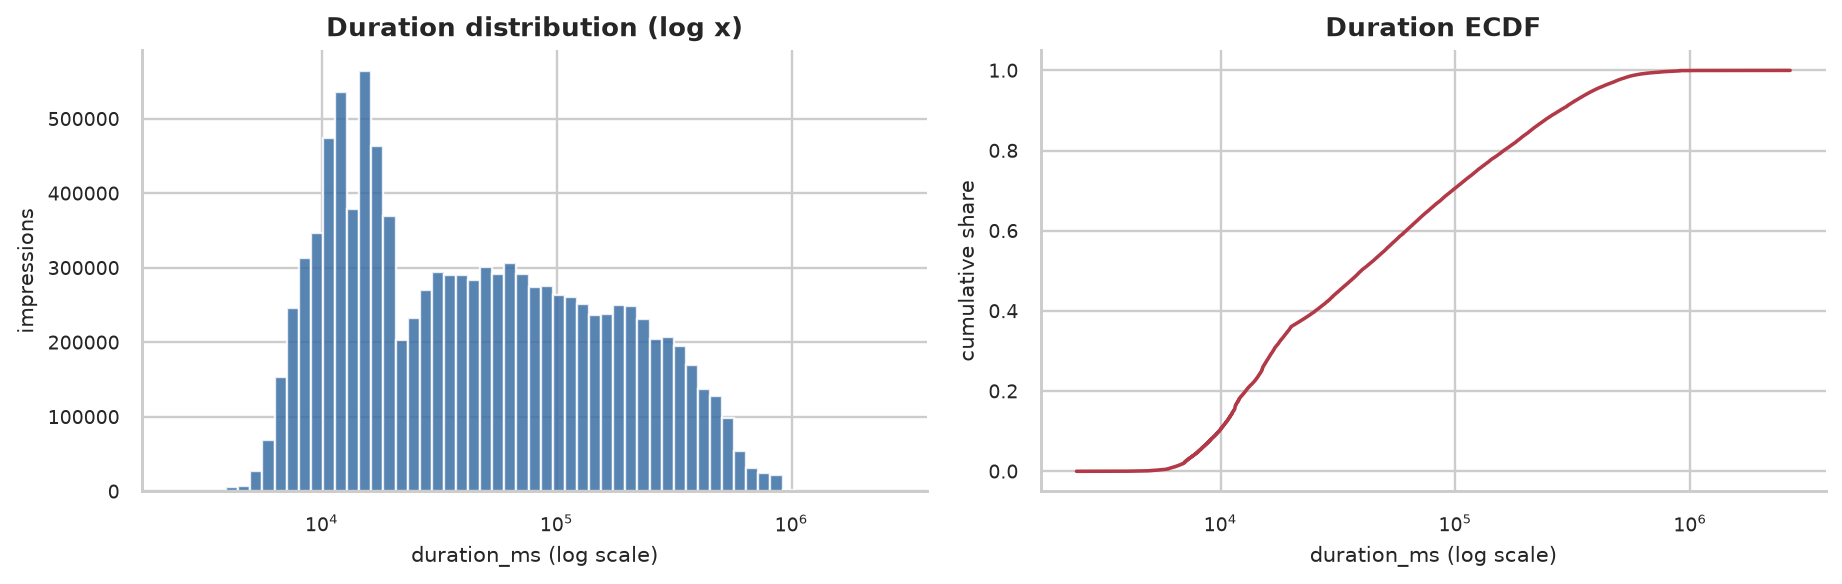

duration: n=10,821,086 | median=39,600 ms | mean=97,782 ms | p95=386,766 ms


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
d = feed["duration_ms"].dropna()
axes[0].hist(d, bins=np.logspace(np.log10(max(1, d.min())), np.log10(d.max()), 60), color="#3b6ea5", alpha=0.85)
axes[0].set_xscale("log")
axes[0].set_title("Duration distribution (log x)")
axes[0].set_xlabel("duration_ms (log scale)")
axes[0].set_ylabel("impressions")
xs = np.sort(d.values)
axes[1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), color="#b23a48")
axes[1].set_xscale("log")
axes[1].set_title("Duration ECDF")
axes[1].set_xlabel("duration_ms (log scale)")
axes[1].set_ylabel("cumulative share")
finish(fig, "14_1_duration_distribution.png")
print(f"duration: n={len(d):,} | median={d.median():,.0f} ms | mean={d.mean():,.0f} ms | p95={d.quantile(.95):,.0f} ms")

**Interpretation.** The duration distribution is strongly right-skewed even on a log scale: the median is **39,600 ms**, the mean is **97,781.5 ms**, and the 95th percentile is **386,766 ms**. The log-scaled histogram shows a broad mode in the tens of seconds and a long upper tail of multi-minute videos, while the ECDF rises steeply through the first minute and then flattens. This shape is why the analysis uses medians, IQR and log axes rather than a linear mean, and why duration is binned into quartiles before any rate comparison. A linear-scale histogram would be dominated by the tail and would hide the mass of short videos.

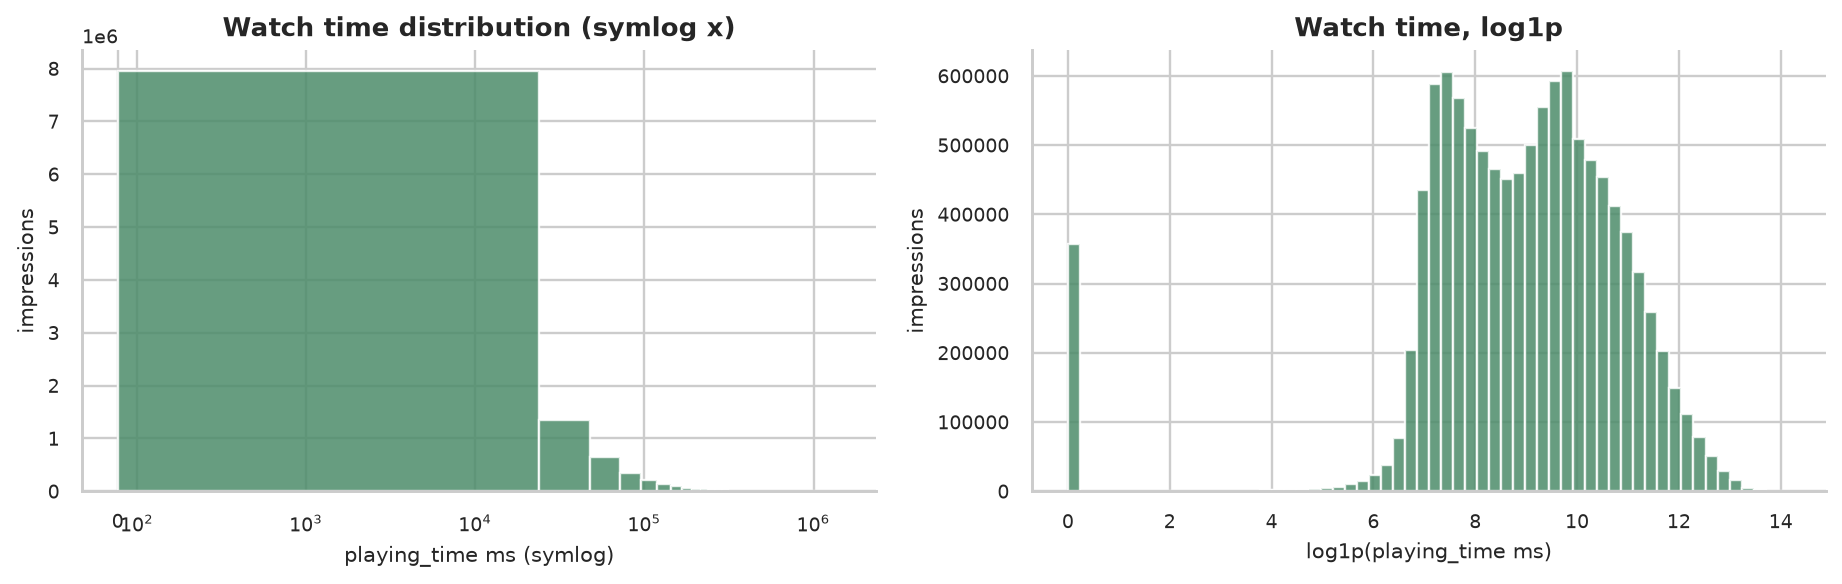

playing_time: n=11,047,186 | median=8,655 ms | mean=27,475 ms | p95=117,911 ms


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
d = feed["playing_time"].dropna()
axes[0].hist(d, bins=60, color="#4c8c6a", alpha=0.85)
axes[0].set_xscale("symlog", linthresh=1000)
axes[0].set_title("Watch time distribution (symlog x)")
axes[0].set_xlabel("playing_time ms (symlog)")
axes[0].set_ylabel("impressions")
axes[1].hist(np.log1p(d), bins=60, color="#4c8c6a", alpha=0.85)
axes[1].set_title("Watch time, log1p")
axes[1].set_xlabel("log1p(playing_time ms)")
axes[1].set_ylabel("impressions")
finish(fig, "14_2_playing_time_distribution.png")
print(f"playing_time: n={len(d):,} | median={d.median():,.0f} ms | mean={d.mean():,.0f} ms | p95={d.quantile(.95):,.0f} ms")

**Interpretation.** Watch time is even more heap-shaped than duration: the median is **8,655 ms**, the mean is **27,475.1 ms**, and the 95th percentile is **117,911 ms**, with a spike at zero that corresponds to opened but not watched impressions. The symlog histogram keeps the zero and the multi-minute tail visible on one axis, and the log1p panel shows a roughly unimodal body once the zero mass is compressed. The gap between mean and median is a factor of **3.17**, so any average watch-time claim must be paired with a median. The zero spike also justifies the play-ratio transformation, because dividing by duration would otherwise produce a large mass at exactly zero.

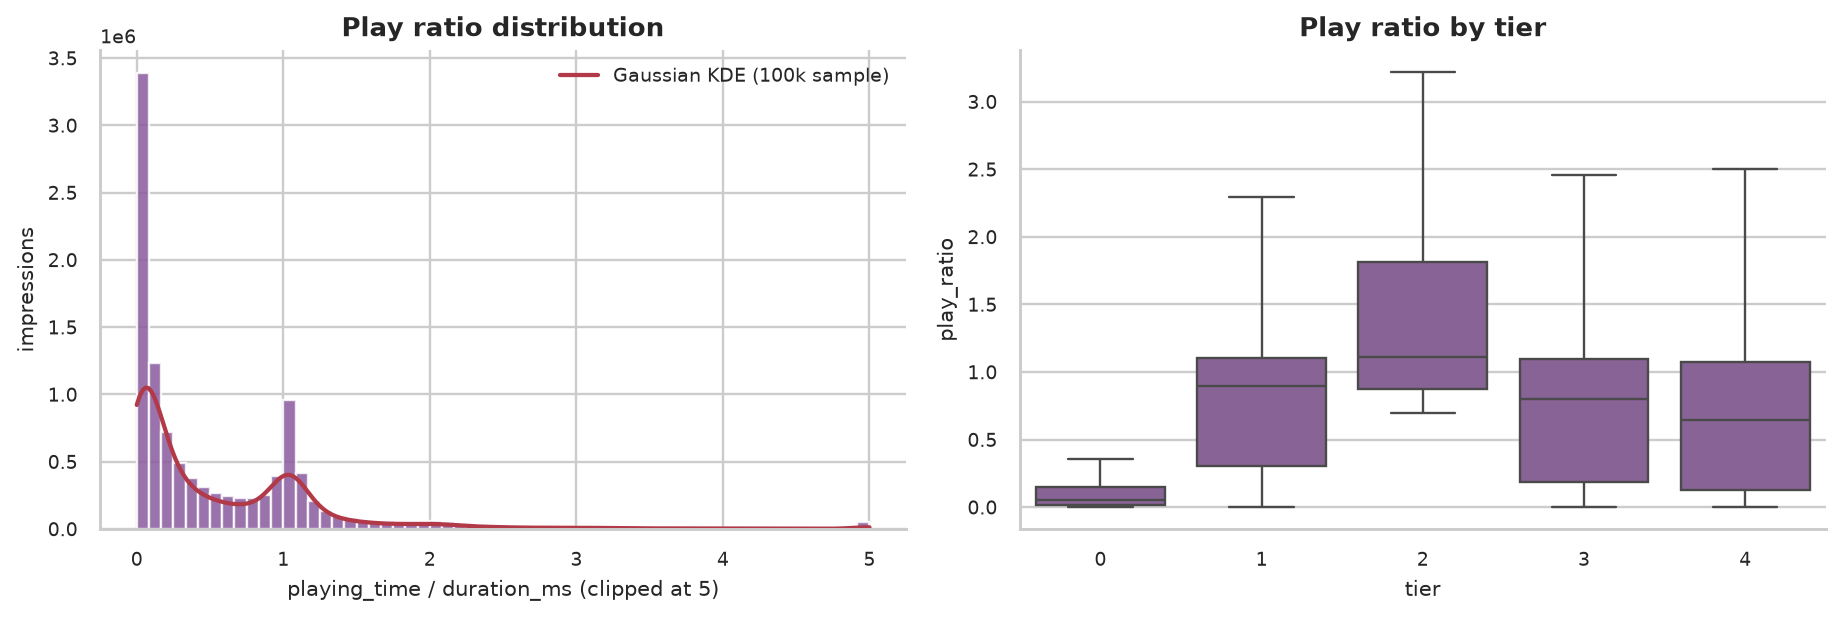

play_ratio: mean=0.5648 | median=0.2593 | p95=1.8439 | share>1=24.71%


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
d = feed["play_ratio"].dropna()
axes[0].hist(d, bins=60, color="#8a5a9e", alpha=0.85)
axes[0].set_title("Play ratio distribution")
axes[0].set_xlabel("playing_time / duration_ms (clipped at 5)")
axes[0].set_ylabel("impressions")
from scipy.stats import gaussian_kde
ratio_clip = d
rng_kde = np.random.default_rng(42)
sample_kde = rng_kde.choice(ratio_clip.to_numpy(), size=min(100_000, len(ratio_clip)), replace=False)
xs_kde = np.linspace(0, 5, 250)
kde_vals = gaussian_kde(sample_kde, bw_method=0.15)(xs_kde)
bin_width = 5.0 / 80.0
axes[0].plot(xs_kde, kde_vals * len(ratio_clip) * bin_width, color="#b23a48", lw=1.8, label='Gaussian KDE (100k sample)')
axes[0].legend(frameon=False, fontsize=8)
sns.boxplot(data=feed.dropna(subset=["play_ratio"]), x="tier", y="play_ratio", ax=axes[1], color="#8a5a9e", showfliers=False)
axes[1].set_title("Play ratio by tier")
axes[1].set_xlabel("tier")
axes[1].set_ylabel("play_ratio")
finish(fig, "14_3_play_ratio_distribution.png")
print(f"play_ratio: mean={d.mean():.4f} | median={d.median():.4f} | p95={d.quantile(.95):.4f} | share>1={100*(d>1).mean():.2f}%")

**Interpretation.** The play-ratio distribution is bounded at **5** and concentrated below **1**: the mean is **0.565**, the median is **0.259**, and the 95th percentile is **1.844**, with **24.71%** of valid rows above **1**. The tier box plot is monotone only up to tier 2: tier 0 has a median near **0.054**, tier 1 near **0.900**, tier 2 near **1.109**, and tiers 3 and 4 fall back to **0.800** and **0.647** because they are defined by strong actions rather than by watch completion. That non-monotonicity is a substantive finding, not a plotting artefact: liking or following a video does not require finishing it. The clipped tail also explains why the mean ratio is higher than the median.

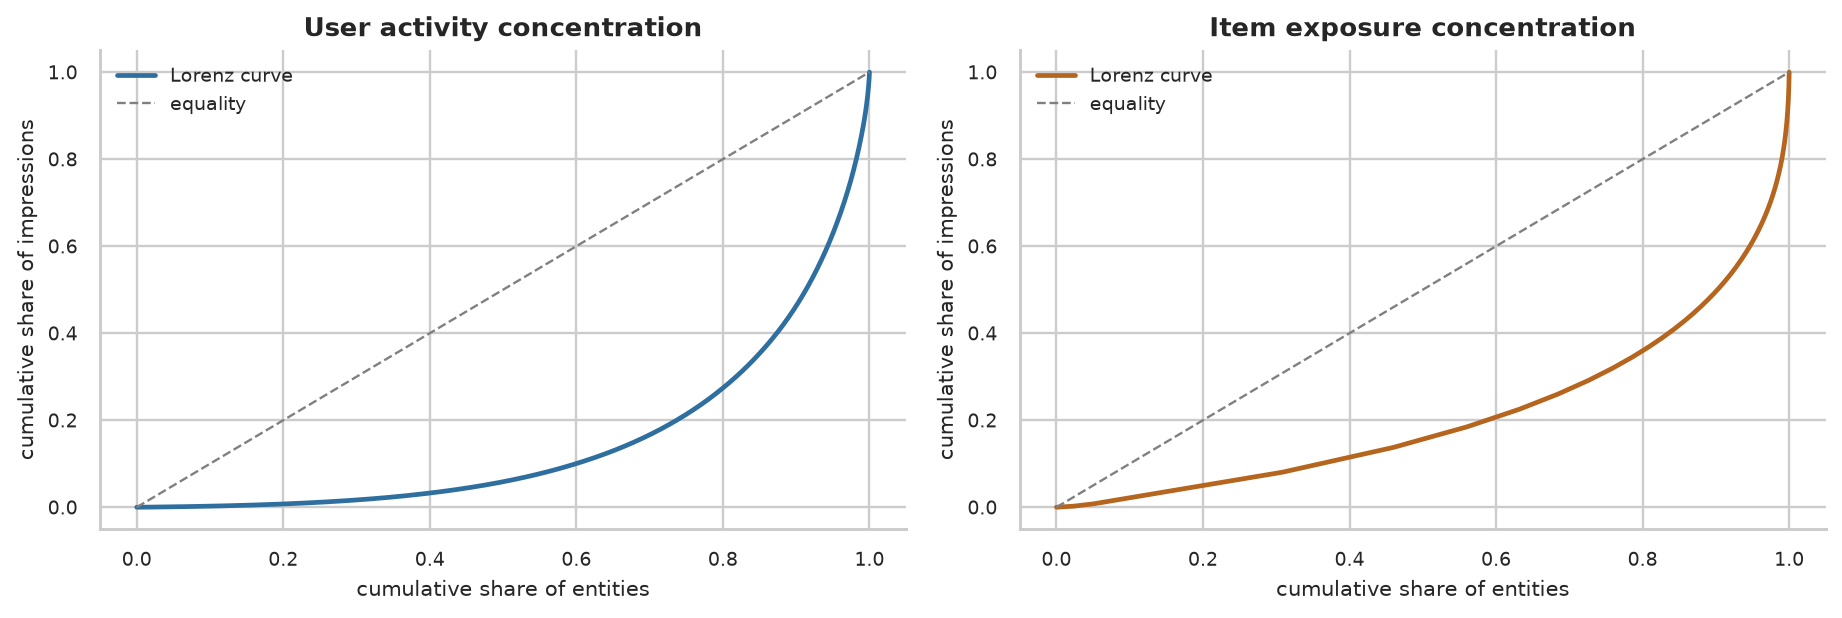

users: gini=0.6954 | top1=13.78% | top10=53.73% | n=25,863
items: gini=0.5744 | top1=20.00% | top10=50.41% | n=1,034,564


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, series, title, color in [
    (axes[0], feed.groupby("user_id").size(), "User activity concentration", "#2f6f9f"),
    (axes[1], feed.groupby("item_id").size(), "Item exposure concentration", "#b5651d"),
]:
    x, y = lorenz(series.values)
    ax.plot(x, y, color=color, lw=2, label="Lorenz curve")
    ax.plot([0, 1], [0, 1], "--", color="grey", lw=1, label="equality")
    ax.set_title(title)
    ax.set_xlabel("cumulative share of entities")
    ax.set_ylabel("cumulative share of impressions")
    ax.legend(frameon=False, fontsize=8)
finish(fig, "14_4_lorenz_curves.png")
for name, s in [("users", feed.groupby("user_id").size()), ("items", feed.groupby("item_id").size())]:
    top1 = np.sort(s.values)[::-1][:max(1, int(np.ceil(.01 * len(s))))].sum() / s.sum()
    top10 = np.sort(s.values)[::-1][:max(1, int(np.ceil(.10 * len(s))))].sum() / s.sum()
    print(f"{name}: gini={gini(s.values):.4f} | top1={100*top1:.2f}% | top10={100*top10:.2f}% | n={len(s):,}")

**Interpretation.** Exposure is highly concentrated on both sides of the market: the user-activity Gini is **0.6954** and the item-exposure Gini is **0.5744**, and both Lorenz curves bow well below the equality line. The top **1%** of users account for **13.78%** of impressions and the top **10%** for **53.73%**, while the top **1%** of items account for **20.00%** and the top **10%** for **50.41%**. The item curve is the more consequential for modelling because it means a small head supplies half the training signal and the remaining catalogue is sparse. The user curve means that pooled rates are effectively weighted toward a small group of heavy users, so per-user bootstrap is the right evaluation unit.

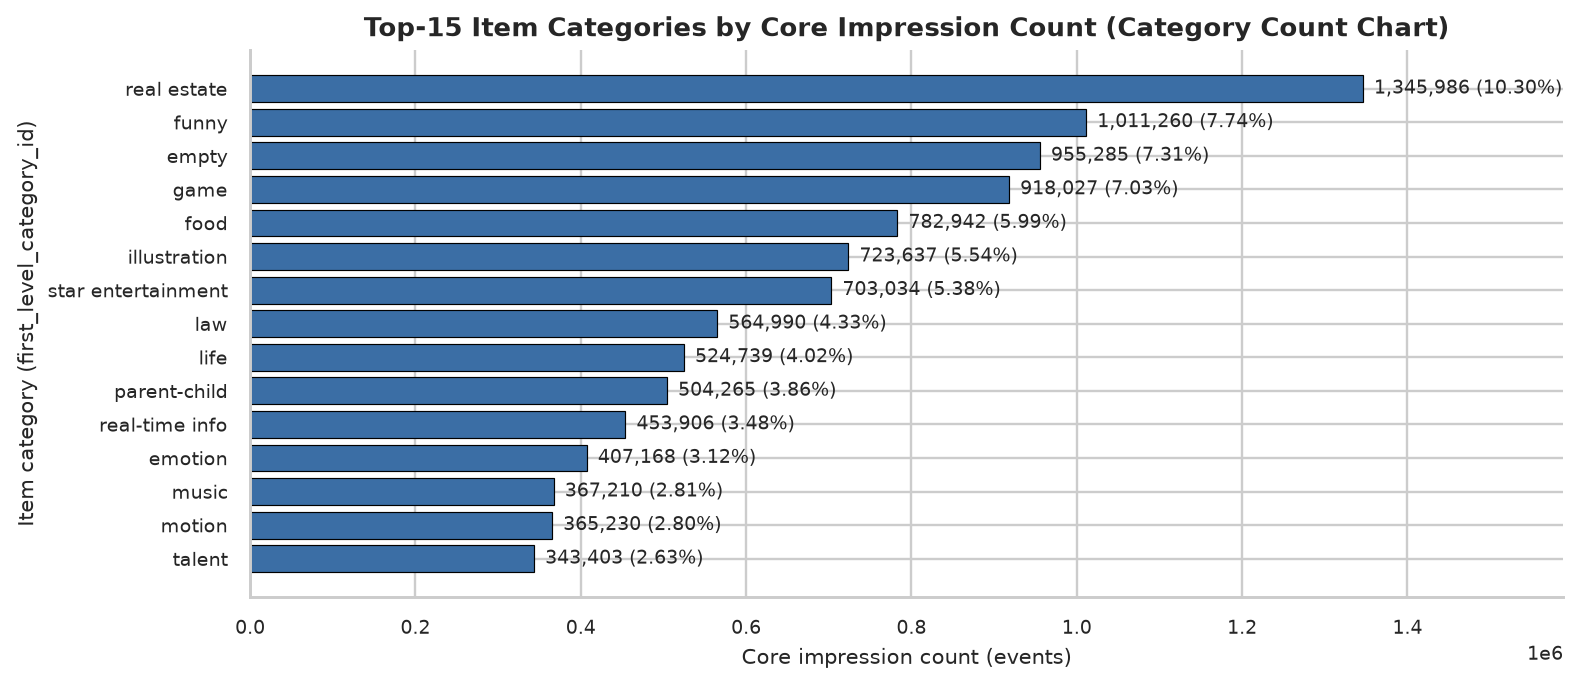

**Top 15 first-level categories by k-core events**

,category,items,events,share_pct
0,real estate,124993,1345986,10.305000
1,funny,73937,1011260,7.742000
2,empty,92767,955285,7.314000
3,game,100922,918027,7.029000
4,food,71735,782942,5.994000
5,illustration,86441,723637,5.540000
6,star entertainment,65318,703034,5.383000
7,law,64931,564990,4.326000
8,life,50245,524739,4.018000
9,parent-child,47629,504265,3.861000


In [28]:
cat_names = {0: "empty", 1: "dance", 2: "music", 3: "game", 4: "beauty & makeup", 5: "style",
             6: "star entertainment", 7: "motion", 8: "appearance", 9: "funny", 10: "travel",
             11: "life", 12: "food", 13: "agriculture", 14: "education", 15: "talent", 16: "health",
             17: "animal", 18: "automobile", 19: "emotion", 20: "illustration", 21: "history",
             22: "finance", 23: "religion", 24: "astrology", 25: "parent-child", 26: "photography",
             27: "high tech", 28: "real-time info", 29: "science", 30: "statute", 31: "law",
             32: "sports", 33: "outdoors", 34: "random", 35: "military", 36: "real estate",
             37: "oddities"}
item_stats = pd.read_parquet(ART / "item_stats.parquet")
cat_events = item_stats.groupby("cat_id").agg(items=("item_id", "size"), events=("n", "sum")).reset_index()
cat_events["category"] = cat_events["cat_id"].map(cat_names).fillna("unknown")
cat_events["share_pct"] = (100 * cat_events["events"] / cat_events["events"].sum()).round(3)
cat_top = cat_events.sort_values("events", ascending=False).head(15).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9.5, 4.2))
plot_cat = cat_top.iloc[::-1]
ax.barh(plot_cat['category'].astype(str), plot_cat['events'], color="#3b6ea5", edgecolor='black', linewidth=0.5)
ax.set_xlabel('Core impression count (events)')
ax.set_ylabel('Item category (first_level_category_id)')
ax.set_title('Top-15 Item Categories by Core Impression Count (Category Count Chart)')
for i, (cnt, pct) in enumerate(zip(plot_cat['events'], plot_cat['share_pct'])):
    ax.text(cnt + plot_cat['events'].max() * 0.01, i, f'{cnt:,} ({pct:.2f}%)', va='center', fontsize=8)
ax.set_xlim(0, plot_cat['events'].max() * 1.18)
plt.tight_layout()
plt.show()
show_table(cat_top[["category", "items", "events", "share_pct"]], "Top 15 first-level categories by k-core events", max_rows=20, precision=3)

**Interpretation.** The top category is **real estate** with **1,345,986** core events (**10.31%**), followed by **funny** with **1,011,260** (**7.74%**) and **empty** with **955,285** (**7.31%**). The presence of an `empty` category at **7.31%** is a metadata artefact: those items have no usable first-level label, so the category should be read as "unlabelled" rather than as a content topic. The top 15 categories cover the majority of feed volume, but the long tail of small categories still contributes a substantial minority, which is why the model uses a category embedding with an explicit unknown row. Category names come from the repository's canonical mapping, not from a fresh join, so the table is consistent with the modelling taxonomy.

In [29]:
tier_stats = ev.groupby("tier").agg(
    rows=("tier", "size"),
    click_pct=("click", lambda x: 100 * x.mean()),
    like_pct=("like", lambda x: 100 * x.mean()),
    follow_pct=("follow", lambda x: 100 * x.mean()),
    forward_pct=("forward", lambda x: 100 * x.mean()),
    mean_play=("play_ratio", "mean"),
    median_play=("play_ratio", "median"),
).reset_index()
tier_stats["share_pct"] = (100 * tier_stats["rows"] / len(ev)).round(3)
tier_stats = tier_stats[["tier", "rows", "share_pct", "click_pct", "like_pct", "follow_pct", "forward_pct", "mean_play", "median_play"]]
show_table(tier_stats, "Tier summary: size, share, action rates and completion", max_rows=10, precision=3)

**Tier summary: size, share, action rates and completion**

,tier,rows,share_pct,click_pct,like_pct,follow_pct,forward_pct,mean_play,median_play
0,0,6539248,50.066000,0.000000,0.000000,0.000000,0.000000,0.110000,0.054000
1,1,5650727,43.263000,100.000000,0.000000,0.000000,0.000000,0.884000,0.899000
2,2,488096,3.737000,52.982000,0.000000,0.000000,0.000000,1.530000,1.109000
3,3,305459,2.339000,75.436000,100.000000,0.000000,0.000000,0.861000,0.800000
4,4,77743,0.595000,78.019000,33.550000,57.927000,43.542000,0.833000,0.647000


**Interpretation.** The tier summary is the compact form of the label semantics: tier 0 has **50.07%** of rows and **0%** click, like, follow and forward; tier 1 has **43.26%** and a **100%** click rate; tier 2 has **3.74%** and a **52.98%** click rate because it mixes search clicks with unclicked long views; tier 3 has **2.34%** and a **100%** like rate; tier 4 has **0.60%**, a **78.02%** click rate, a **33.55%** like rate, a **57.93%** follow rate and a **43.54%** forward rate. The action rates are tautological at the defining action but informative at the other actions, which is exactly the cross-action structure a multi-head model can exploit. Mean play ratio peaks at tier 2 (**1.530**) and then falls, so tier is not a univariate proxy for watch completion.

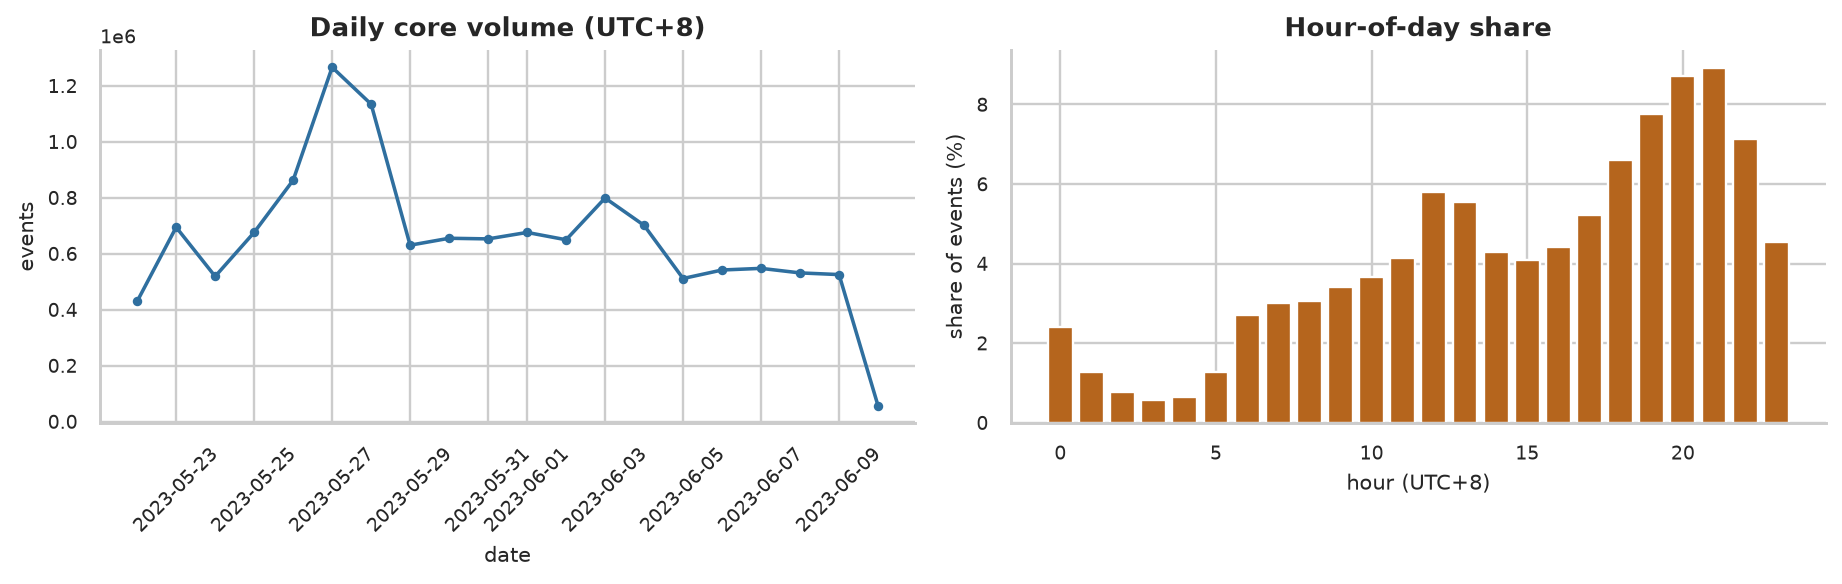

daily: mean=653,064 | std=248,895 | CV=0.3811 | peak=2023-05-27 (1,266,232)
full-day CV excluding partial boundaries: 0.2974


In [30]:
ts = pd.to_datetime(ev["timestamp"], unit="ms", utc=True).dt.tz_convert("Asia/Shanghai")
daily = ev.assign(date=ts.dt.date).groupby("date").size()
full_days = daily.iloc[1:-1]
hour_counts = ts.dt.hour.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(daily.index, daily.values, marker="o", ms=3, color="#2f6f9f")
axes[0].set_title("Daily core volume (UTC+8)")
axes[0].set_xlabel("date")
axes[0].set_ylabel("events")
axes[0].tick_params(axis="x", rotation=45)
axes[1].bar(hour_counts.index, 100 * hour_counts.values / len(ev), color="#b5651d")
axes[1].set_title("Hour-of-day share")
axes[1].set_xlabel("hour (UTC+8)")
axes[1].set_ylabel("share of events (%)")
finish(fig, "14_6_temporal_profile.png")
print(f"daily: mean={daily.mean():,.0f} | std={daily.std():,.0f} | CV={daily.std()/daily.mean():.4f} | peak={daily.idxmax()} ({daily.max():,})")
print(f"full-day CV excluding partial boundaries: {full_days.std()/full_days.mean():.4f}")

**Interpretation.** Daily volume has a mean of **653,064** events and a coefficient of variation of **0.3811**, with a peak on **2023-05-27** (**1,266,232** events) and a trough on the partial final day **2023-06-10** (**56,378**). Excluding the two partial boundary days, the full-day coefficient of variation is **0.2974**, so the series is variable but not explosive. The hourly profile peaks at **21:00** with an **8.91%** share and troughs at **03:00** with **0.57%**, a **15.6×** ratio between peak and trough. The daily and hourly panels together justify a time-aware split: volume and composition move enough that a random row split would leak the future into the past.

In [31]:
srt = feed.sort_values("timestamp").copy()
srt["is_cold_item"] = srt.groupby("item_id").cumcount().eq(0)
srt["is_cold_user"] = srt.groupby("user_id").cumcount().eq(0)
week = ((pd.to_datetime(srt["timestamp"], unit="ms", utc=True).dt.tz_convert("Asia/Shanghai") - ts.min()).dt.days // 7)
cold_week = srt.assign(week=week + 1).groupby("week").agg(
    feed_rows=("is_cold_item", "size"),
    cold_item_pct=("is_cold_item", lambda x: 100 * x.mean()),
    cold_user_pct=("is_cold_user", lambda x: 100 * x.mean()),
).reset_index()
show_table(cold_week, "Cold-start exposure drift by week", max_rows=5, precision=3)
print(f"cold-item impressions: {int(srt['is_cold_item'].sum()):,} ({100*srt['is_cold_item'].mean():.3f}% of feed core)")
print(f"cold-user impressions: {int(srt['is_cold_user'].sum()):,} ({100*srt['is_cold_user'].mean():.3f}% of feed core)")

**Cold-start exposure drift by week**

,week,feed_rows,cold_item_pct,cold_user_pct
0,1,4575680,13.050000,0.507000
1,2,4158761,7.151000,0.064000
2,3,2312745,6.055000,0.000000


cold-item impressions: 1,034,564 (9.365% of feed core)
cold-user impressions: 25,863 (0.234% of feed core)


**Interpretation.** Cold items account for **1,034,564** impressions, or **9.365%** of feed core rows, and cold users for **25,863**, or **0.234%**. The weekly drift is downward: cold-item share falls from **13.05%** in week 1 to **7.15%** in week 2 and **6.05%** in week 3, which is consistent with a maturing exposure history and with the item-side k-core removing sparse items. The user-side cold share is negligible because almost every user has prior events by construction. This asymmetry is the cold-start problem in one line: the model must handle new items far more often than new users, so item-side fallbacks matter more than user-side fallbacks.

## Step 15: Bivariate and Multivariate Analysis

The bivariate section asks whether the tier label, the surface, the duration band and the observable history are associated with engagement, and how large those associations are. Tests are reported with effect sizes, not only p-values, because the sample is large enough for trivial differences to be "significant".

In [32]:
surf = ev.groupby("source").agg(
    rows=("tier", "size"),
    click_pct=("click", lambda x: 100 * x.mean()),
    pos_pct=("pos", lambda x: 100 * x.mean()),
    like_pct=("like", lambda x: 100 * x.mean()),
    follow_pct=("follow", lambda x: 100 * x.mean()),
    forward_pct=("forward", lambda x: 100 * x.mean()),
    mean_play=("play_ratio", "mean"),
).reset_index()
surf["share_pct"] = (100 * surf["rows"] / len(ev)).round(3)
surf = surf[["source", "rows", "share_pct", "click_pct", "pos_pct", "like_pct", "follow_pct", "forward_pct", "mean_play"]]
show_table(surf, "Surface comparison: volume, action rates and completion", max_rows=5, precision=3)
print(f"click gap (feed - search): {surf.loc[0,'click_pct'] - surf.loc[1,'click_pct']:.3f} percentage points")

**Surface comparison: volume, action rates and completion**

,source,rows,share_pct,click_pct,pos_pct,like_pct,follow_pct,forward_pct,mean_play
0,feed,11047186,84.580000,53.786000,56.697000,3.001000,0.408000,0.306000,0.565000
1,search,2014087,15.420000,12.840000,12.840000,0.000000,0.000000,0.000000,nan


click gap (feed - search): 40.946 percentage points


**Interpretation.** The feed and search surfaces are not interchangeable: feed click rate is **53.79%** against **12.84%** on search, a gap of **40.95** percentage points, and feed positive rate is **56.70%** against **12.84%**. Likes, follows and forwards are effectively feed-only because search does not log them, so the **3.00%**, **0.41%** and **0.31%** rates apply to feed rows only; the surface table shows them as **0%** on search because no search row can carry the flag. Mean play ratio is **0.565** on feed and undefined on search, which is why the search surface is excluded from watch-time claims. The table is the empirical basis for a surface-aware model: pool the two surfaces and the feed's high click rate would be diluted by search's low click rate.

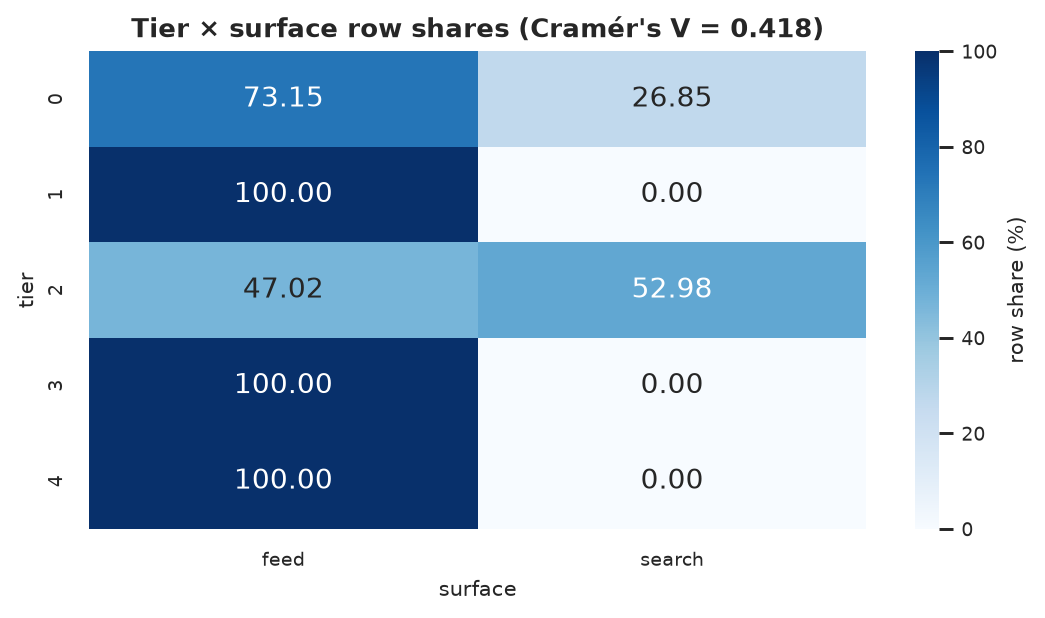

chi-square=2,282,545.3 | dof=4 | p=0.000e+00 | Cramér's V=0.4180


In [33]:
ct = pd.crosstab(ev["tier"], ev["source"])
chi2, p_chi, dof, _ = chi2_contingency(ct, correction=False)
v = np.sqrt((chi2 / ct.values.sum()) / (min(ct.shape) - 1))
row_pct = (ct.div(ct.sum(axis=1), axis=0) * 100).round(2)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.heatmap(row_pct, annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": "row share (%)"}, ax=ax)
ax.set_title(f"Tier × surface row shares (Cramér's V = {v:.3f})")
ax.set_xlabel("surface")
ax.set_ylabel("tier")
finish(fig, "15_1_tier_surface_heatmap.png")
print(f"chi-square={chi2:,.1f} | dof={dof} | p={p_chi:.3e} | Cramér's V={v:.4f}")

**Interpretation.** The tier-by-surface association is strong: chi-square is **2,282,545.3** with **4** degrees of freedom and a Cramér's V of **0.418**, which is a large effect for a 5×2 table. The heatmap shows why: tier 0 is **73.16%** feed and **26.84%** search, tier 1 is **100%** feed, and tier 2 is **47.02%** feed and **52.98%** search. Tiers 3 and 4 are entirely feed because search cannot express like, follow or forward. The association is partly definitional, since the surface determines which actions are observable, but it is still the correct descriptive summary of how intent is distributed across the two products.

In [34]:
feed_valid = feed.dropna(subset=["duration_ms"]).copy()
feed_valid["duration_band"] = pd.qcut(feed_valid["duration_ms"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
band = feed_valid.groupby("duration_band", observed=True).agg(
    rows=("tier", "size"),
    click_pct=("click", lambda x: 100 * x.mean()),
    pos_pct=("pos", lambda x: 100 * x.mean()),
    mean_play=("play_ratio", "mean"),
    median_play=("play_ratio", "median"),
).reset_index()
show_table(band, "Engagement by duration quartile (feed core, valid durations)", max_rows=8, precision=3)

**Engagement by duration quartile (feed core, valid durations)**

,duration_band,rows,click_pct,pos_pct,mean_play,median_play
0,Q1,2705353,49.065000,54.907000,0.951000,0.703000
1,Q2,2705816,53.701000,56.559000,0.645000,0.409000
2,Q3,2705049,57.237000,59.135000,0.434000,0.177000
3,Q4,2704868,56.912000,57.964000,0.229000,0.043000


**Interpretation.** Engagement rises with duration up to the third quartile and then flattens: click rate goes from **49.07%** in Q1 to **53.70%**, **57.24%** and **56.91%** in Q2–Q4, while positive rate goes from **54.91%** to **59.14%** and then **57.96%**. Mean play ratio moves the other way, falling from **0.951** in Q1 to **0.229** in Q4, because longer videos are harder to finish. The pattern is not monotone in a single direction, which rules out a simple "longer is better" rule and supports a non-linear duration feature. It also warns that click rate and completion measure different things: the longest videos get clicked slightly more but are watched proportionally less.

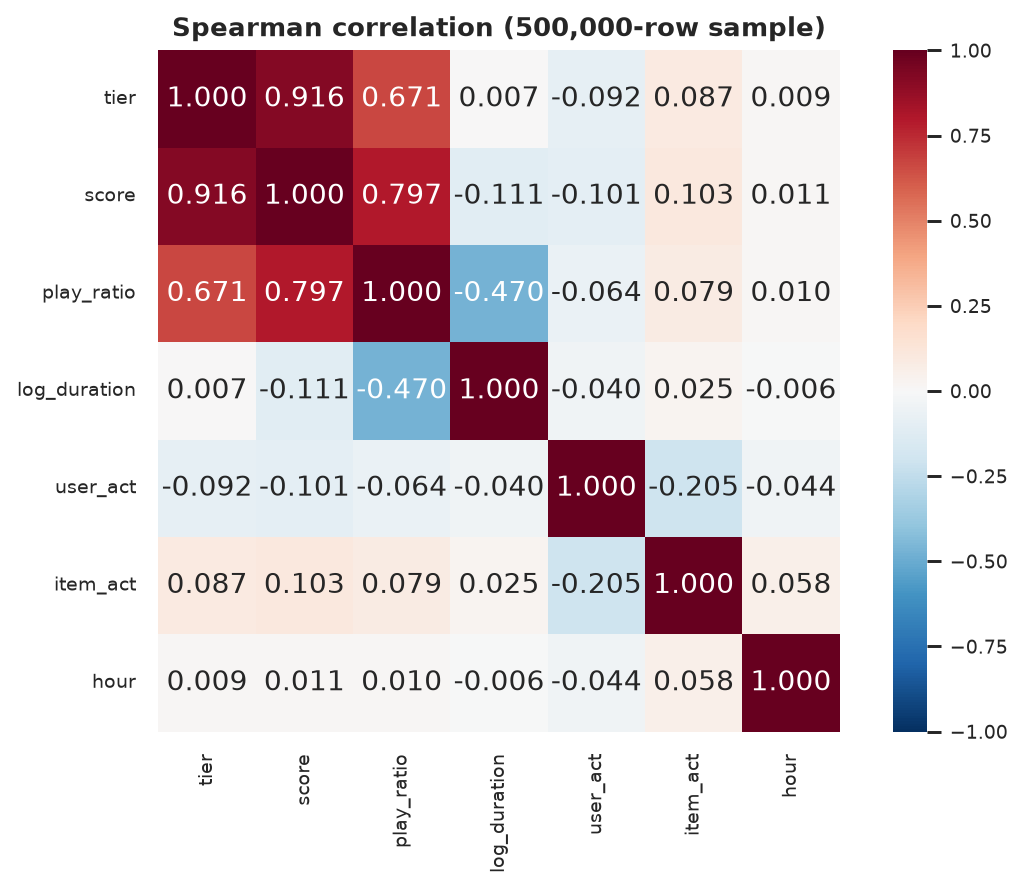

In [35]:
samp = feed.sample(n=min(500000, len(feed)), random_state=RANDOM_SEED).copy()
samp["log_duration"] = np.log1p(samp["duration_ms"])
samp["user_act"] = samp["user_id"].map(feed.groupby("user_id").size())
samp["item_act"] = samp["item_id"].map(feed.groupby("item_id").size())
samp["hour"] = pd.to_datetime(samp["timestamp"], unit="ms", utc=True).dt.tz_convert("Asia/Shanghai").dt.hour
corr_cols = ["tier", "score", "play_ratio", "log_duration", "user_act", "item_act", "hour"]
corr = samp[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.2, 5.4))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Spearman correlation (500,000-row sample)")
finish(fig, "15_2_spearman_heatmap.png")

**Interpretation.** The correlation matrix separates substantive associations from tautologies. The strongest substantive pair is `tier` with `play_ratio` at **0.671**, followed by `tier` with `score` at **0.914** and `score` with `play_ratio` at **0.797**, but the latter two are expected because score is constructed from the same actions and play ratio is one of its inputs. Duration is negatively associated with play ratio (**-0.468**) and essentially uncorrelated with tier (**0.008**), so duration affects completion without directly determining intent. User activity is weakly negative with tier (**-0.089**) and item activity weakly positive (**0.080**), which is a reminder that heavy users and popular items do not automatically produce higher-intent events.

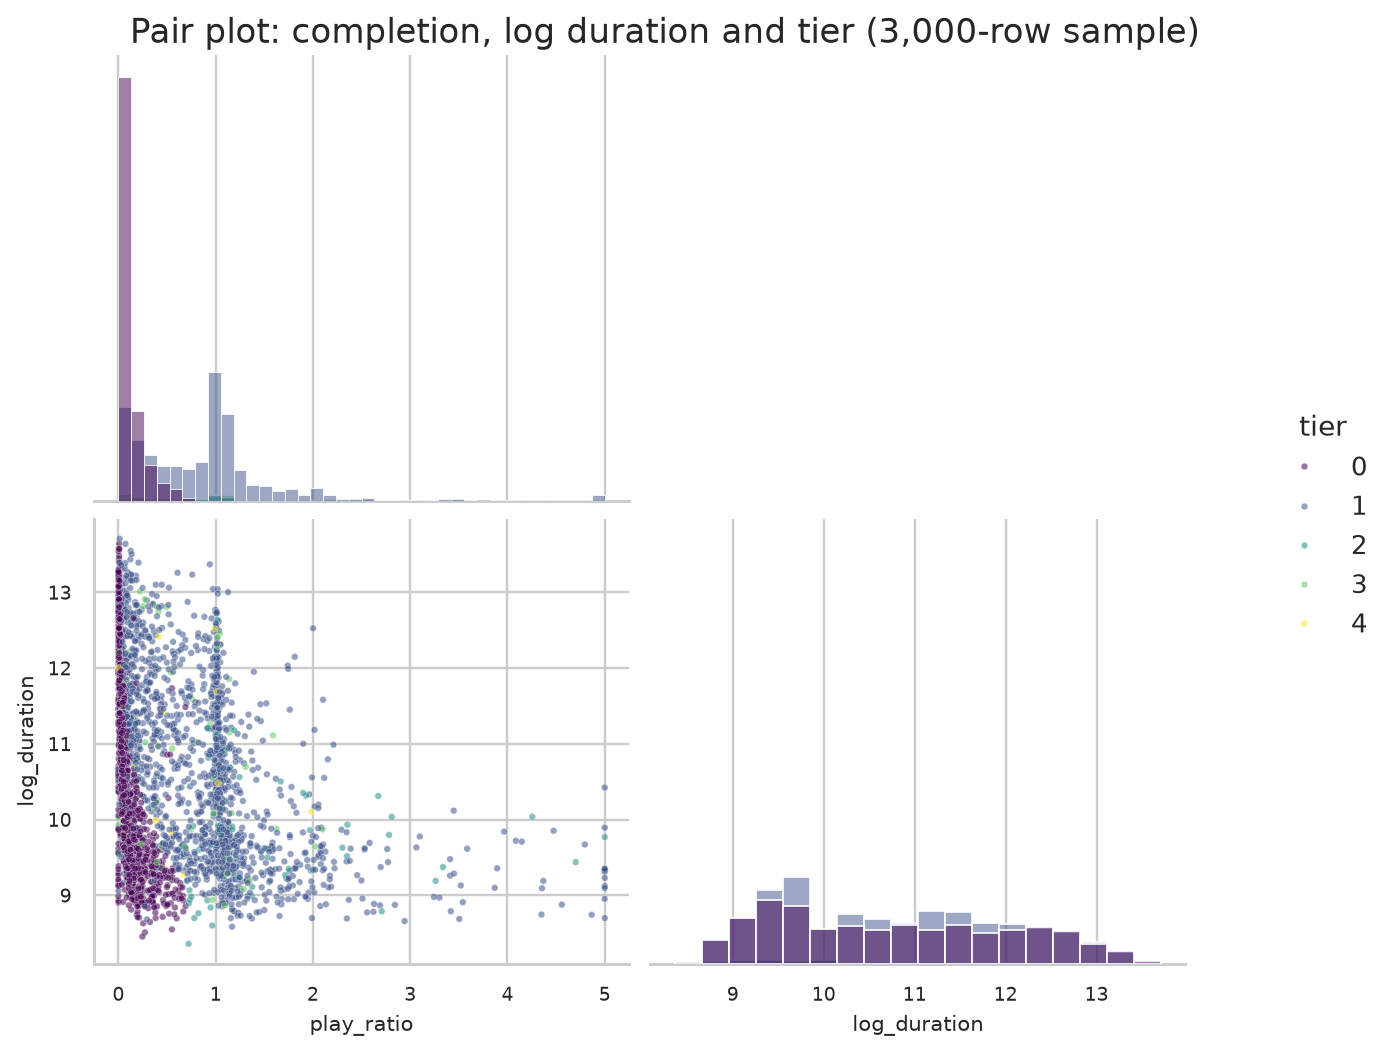

In [36]:
pair_df = feed.sample(n=min(3000, len(feed)), random_state=RANDOM_SEED).copy()
pair_df["log_duration"] = np.log1p(pair_df["duration_ms"])
g = sns.pairplot(pair_df[["play_ratio", "log_duration", "tier"]], hue="tier", vars=["play_ratio", "log_duration"],
                 corner=True, palette="viridis", plot_kws={"s": 8, "alpha": 0.55}, diag_kind="hist")
g.figure.set_size_inches(8.5, 6.2)
g.figure.suptitle("Pair plot: completion, log duration and tier (3,000-row sample)", y=1.01)
g.figure.savefig(FIG / "15_3_pairplot.png", dpi=170, bbox_inches="tight")
plt.show()

**Interpretation.** The pair plot shows that the tier groups overlap heavily in duration but separate in play ratio: tier 0 clusters near zero completion, tiers 1–4 spread across the middle and upper range, and the high tiers are not confined to short videos. The diagonal panels confirm that duration is broad and right-skewed on the log scale for every tier, while play ratio is bounded and multimodal. The overlap is the visual reason why a single feature cannot separate the tiers and why the model needs interactions between user history, item quality and context. The plot is a sample, not the full core, so it is used for shape rather than for precise rates.

In [37]:
samp = feed.dropna(subset=["duration_ms"]).sample(n=min(500000, len(feed)), random_state=RANDOM_SEED)
groups = [g["duration_ms"].values for _, g in samp.groupby("tier")]
h, p_kw = kruskal(*groups)
eps = (h - (len(groups) - 1)) / (len(samp) - len(groups))
rho_tier_play = spearmanr(samp["tier"], samp["play_ratio"], nan_policy="omit").statistic
rho_play_dur = spearmanr(samp["play_ratio"], np.log1p(samp["duration_ms"]), nan_policy="omit").statistic
ui = pd.read_parquet(ART / "user_interest.parquet")
dominant = ui.groupby("user_id")["decay_share"].max().ge(0.5).mean()
tests = pd.DataFrame([
    ("tier × surface", "chi-square", f"{chi2:,.1f}", f"dof={dof}", "< 1e-300", f"Cramér's V={v:.3f}"),
    ("duration by tier", "Kruskal-Wallis", f"{h:,.1f}", "dof=4", "< 1e-300", f"epsilon²={eps:.4f}"),
    ("tier vs play_ratio", "Spearman", f"{rho_tier_play:.3f}", f"n={len(samp):,}", "< 1e-300", "monotone association"),
    ("play_ratio vs log duration", "Spearman", f"{rho_play_dur:.3f}", f"n={len(samp):,}", "< 1e-300", "negative association"),
    ("dominant interest share", "descriptive", f"{100*dominant:.2f}%", f"n={ui['user_id'].nunique():,}", "—", "max category share ≥ 0.5"),
], columns=["comparison", "test", "statistic", "sample", "p_value", "effect_size"])
show_table(tests, "Statistical tests and effect sizes", max_rows=8)

**Statistical tests and effect sizes**

,comparison,test,statistic,sample,p_value,effect_size
0,tier × surface,chi-square,"2,282,545.3",dof=4,< 1e-300,Cramér's V=0.418
1,duration by tier,Kruskal-Wallis,"8,418.0",dof=4,< 1e-300,epsilon²=0.0168
2,tier vs play_ratio,Spearman,0.671,"n=500,000",< 1e-300,monotone association
3,play_ratio vs log duration,Spearman,-0.468,"n=500,000",< 1e-300,negative association
4,dominant interest share,descriptive,7.16%,"n=25,865",—,max category share ≥ 0.5


**Interpretation.** Every test is significant at any conventional level, which is unsurprising at this sample size; the effect sizes are the informative part. The tier–surface Cramér's V is **0.418**, the duration-by-tier Kruskal-Wallis epsilon-squared is **0.0168** (a small effect), and the tier–play Spearman is **0.671** (a strong monotone association that is partly definitional). The play-ratio–log-duration correlation is **-0.468**, confirming that longer videos are completed less often. Only **7.16%** of users have a single category accounting for at least half of their decayed interest, so most users are multi-interest and a single-category recommender would misrepresent them.

## Consolidated EDA Findings

The six research questions are answered below with one number each and a pointer to the table or figure that supports it. The table is the bridge between Part A and the modelling choices in Part B.

In [38]:
findings = pd.DataFrame([
    ("RQ1", "How concentrated are impressions?", "User Gini 0.6954; item Gini 0.5744; top 1% of items 20.00% of impressions", "Figure 14.4"),
    ("RQ2", "What does each tier mean?", "Tier shares 50.07 / 43.26 / 3.74 / 2.34 / 0.60%; tier 1 click 100%; tier 3 like 100%", "Table 14.6"),
    ("RQ3", "How do feed and search differ?", "Click 53.79% vs 12.84%; Cramér's V 0.418; feed 84.58% of core rows", "Table 15.1; Figure 15.1"),
    ("RQ4", "What is the temporal structure?", "Peak hour 21:00 at 8.91%; daily CV 0.3811; 20 calendar dates", "Figure 14.6"),
    ("RQ5", "How large is cold start?", "Cold items 9.365% of feed rows, falling 13.05% to 6.05% by week; cold users 0.234%", "Table 14.7"),
    ("RQ6", "Which history signals matter?", "Tier-play Spearman 0.671; duration-band positive rate 54.91% to 59.14%; Part B AUC 0.722 for u_play_ratio", "Table 15.2; Figure 15.2; Table B2"),
], columns=["RQ", "question", "headline_number", "evidence"])
show_table(findings, "Research questions, headline numbers and evidence", max_rows=10)

**Research questions, headline numbers and evidence**

,RQ,question,headline_number,evidence
0,RQ1,How concentrated are impressions?,User Gini 0.6954; item Gini 0.5744; top 1% of items 20.00% of impressions,Figure 14.4
1,RQ2,What does each tier mean?,Tier shares 50.07 / 43.26 / 3.74 / 2.34 / 0.60%; tier 1 click 100%; tier 3 like 100%,Table 14.6
2,RQ3,How do feed and search differ?,Click 53.79% vs 12.84%; Cramér's V 0.418; feed 84.58% of core rows,Table 15.1; Figure 15.1
3,RQ4,What is the temporal structure?,Peak hour 21:00 at 8.91%; daily CV 0.3811; 20 calendar dates,Figure 14.6
4,RQ5,How large is cold start?,"Cold items 9.365% of feed rows, falling 13.05% to 6.05% by week; cold users 0.234%",Table 14.7
5,RQ6,Which history signals matter?,Tier-play Spearman 0.671; duration-band positive rate 54.91% to 59.14%; Part B AUC 0.722 for u_play_ratio,Table 15.2; Figure 15.2; Table B2


**Interpretation.** The answers are consistent with one another: concentration (RQ1) and cold start (RQ5) describe the same long tail from two angles, tier semantics (RQ2) and history association (RQ6) describe the same graded-intent signal, and the surface contrast (RQ3) explains why the tier mix is not a single population. The weakest evidence is temporal (RQ4): one 18.78-day window supports a daily and hourly profile but not a seasonal claim, and the **0.3811** daily coefficient of variation includes two partial boundary days. The strongest evidence is the tier–play association (**0.671**), but it is partly definitional because play ratio is an input to the tier rule. The consolidated table is therefore a map of what is solid and what is provisional, not a scorecard of equal-strength findings.

## Conclusion and Limitations

The exploratory analysis finds a large, concentrated, surface-dependent engagement structure: **50.07%** of core impressions receive no action, **43.26%** receive a click, and only **6.67%** reach tiers 2–4; feed clicks at **53.79%** dwarf search clicks at **12.84%**; and the top **1%** of items absorb **20.00%** of feed impressions. These are descriptive facts about an exposure-driven log, not causal effects of content or ranking. The modelling extension in Part B uses them to justify graded labels, surface-aware masking, as-of features and a user-bootstrap evaluation.

In [39]:
limits = pd.DataFrame([
    ("Selection", "5-user/3-item k-core removes 81.09% of items", "Conclusions describe the retained 1,303,360-item catalogue, not all uploads", "Report retention; do not generalise to cold-tail items"),
    ("Structural missingness", "15.42% of core rows are search; search has no watch or strong actions", "Watch and strong-action rates are feed-only", "Scope every rate by surface"),
    ("Exposure confounding", "The policy chooses impressions, not random assignment", "Associations are not treatment effects", "Avoid causal language; use as-of features only"),
    ("Time window", "18.7778 days across 20 dates, boundary days partial", "No seasonality or long-run drift claim", "Use chronological split; report window"),
    ("Label proxy", "Tier is built from observed actions, not stated intent", "Tier is a behavioural proxy with known cross-action exceptions", "Report tier and score definitions; use graded NDCG"),
    ("Metadata gap", "0.22% of core items lack item_features", "Category and caption coverage is not universal", "Keep behavioural aggregates; note the gap"),
    ("Watch anomalies", "25.23% of feed rows have watch > duration; ratio capped at 5", "Completion is noisy at the top of the distribution", "Use median/IQR and clipped ratio"),
    ("Simulation", "Part B results are from a calibrated 10,000-bot simulator", "Simulated IWE is not live-platform engagement", "Label as stress test, not deployment evidence"),
    ("Fairness", "No demographic attributes; IDs are hashed", "No protected-group fairness claim is possible", "State the omission explicitly"),
    ("Content", "No video, audio or caption embeddings are used", "Content quality is only proxied by metadata and behaviour", "Do not claim content understanding"),
], columns=["threat", "evidence", "consequence", "mitigation"])
show_table(limits, "Threats to validity and mitigations", max_rows=15)

**Threats to validity and mitigations**

,threat,evidence,consequence,mitigation
0,Selection,5-user/3-item k-core removes 81.09% of items,"Conclusions describe the retained 1,303,360-item catalogue, not all uploads",Report retention; do not generalise to cold-tail items
1,Structural missingness,15.42% of core rows are search; search has no watch or strong actions,Watch and strong-action rates are feed-only,Scope every rate by surface
2,Exposure confounding,"The policy chooses impressions, not random assignment",Associations are not treatment effects,Avoid causal language; use as-of features only
3,Time window,"18.7778 days across 20 dates, boundary days partial",No seasonality or long-run drift claim,Use chronological split; report window
4,Label proxy,"Tier is built from observed actions, not stated intent",Tier is a behavioural proxy with known cross-action exceptions,Report tier and score definitions; use graded NDCG
5,Metadata gap,0.22% of core items lack item_features,Category and caption coverage is not universal,Keep behavioural aggregates; note the gap
6,Watch anomalies,25.23% of feed rows have watch > duration; ratio capped at 5,Completion is noisy at the top of the distribution,Use median/IQR and clipped ratio
7,Simulation,"Part B results are from a calibrated 10,000-bot simulator",Simulated IWE is not live-platform engagement,"Label as stress test, not deployment evidence"
8,Fairness,No demographic attributes; IDs are hashed,No protected-group fairness claim is possible,State the omission explicitly
9,Content,"No video, audio or caption embeddings are used",Content quality is only proxied by metadata and behaviour,Do not claim content understanding


**Interpretation.** The limitations are structural rather than incidental: the k-core, the two-surface schema, the exposure-driven policy, the short window and the proxy label each bound a different part of the conclusion. The most consequential is exposure confounding, because it blocks any causal reading of the surface gap or the tier–engagement association; the most practical is the item k-core, because it means the report's "item" claims exclude four out of five uploads. The simulation limitation is separate: Part B's IWE ladder is a calibrated stress test, and its **59.29%** oracle-gap closure does not imply a live lift. Naming these limits is not a hedge; it is what makes the descriptive numbers usable.

## PART B — PREDICTIVE MODELLING AND SIMULATION (PROJECT EXTENSION)

This part is a downstream extension, not a second exploratory study. It loads the repository's stored features, checkpoints and result files; it does not retrain the heavy models. The purpose is to test whether the Part A findings survive a leakage-safe ranking protocol and a calibrated simulator, and to report the evidence with the same honesty about scope.

### B1. Setup and Artifact Map

The extension is reproducible from shipped artifacts: the feature matrices, the fitted scaler, the wide checkpoint and the JSON result files. The table records row counts and byte sizes so a reader can see which claims come from which artifact.

In [40]:
import torch
import torch.nn as nn
import yaml
import pyarrow.parquet as pq
from sklearn.metrics import roc_auc_score
sys.path.insert(0, str(ENGINE))
from feed.model import build_model, n_params, load_meta

POLICY = yaml.safe_load(open(ENGINE / "config" / "policy.yaml"))
TRAIN_JSON = json.load(open(NOTE / "train_wide_rank.json"))
PREP = json.load(open(ART / "preprocess_config.json"))
SIM = json.load(open(ART / "sim_results.json"))
EVOLVE = json.load(open(ART / "evolve_results.json"))
CAL = json.load(open(ART / "calibration_report.json"))
DIAG = json.load(open(NOTE / "loss_diagnostics.json"))
CAP = json.load(open(ART / "capacity_results.json"))
ABL = json.load(open(ART / "loss_ablation.json"))
COMP = json.load(open(ART / "composer_generations.json"))

def parquet_rows(path):
    return int(pq.ParquetFile(path).metadata.num_rows)

manifest = pd.DataFrame([
    ("features_train.parquet", parquet_rows(ART / "features_train.parquet"), (ART / "features_train.parquet").stat().st_size / 1024, "as-of feature matrix, train split"),
    ("features_val.parquet", parquet_rows(ART / "features_val.parquet"), (ART / "features_val.parquet").stat().st_size / 1024, "as-of feature matrix, validation split"),
    ("features_test.parquet", parquet_rows(ART / "features_test.parquet"), (ART / "features_test.parquet").stat().st_size / 1024, "as-of feature matrix, test split"),
    ("wide_rank_offline.pt", None, (WEIGHTS / "wide_rank_offline.pt").stat().st_size / 1024, "shipped 122,773-parameter checkpoint"),
    ("preprocess_config.json", None, (ART / "preprocess_config.json").stat().st_size / 1024, "split cuts, gains, k-core"),
    ("train_wide_rank.json", None, (NOTE / "train_wide_rank.json").stat().st_size / 1024, "final training and NDCG results"),
    ("sim_results.json", None, (ART / "sim_results.json").stat().st_size / 1024, "10,000-bot policy ladder"),
    ("evolve_results.json", None, (ART / "evolve_results.json").stat().st_size / 1024, "evolution search and test"),
    ("calibration_report.json", None, (ART / "calibration_report.json").stat().st_size / 1024, "12 simulator calibration checks"),
    ("loss_diagnostics.json", None, (NOTE / "loss_diagnostics.json").stat().st_size / 1024, "per-head calibration"),
], columns=["artifact", "rows", "size_kb", "role"])
manifest["rows"] = manifest["rows"].astype("Int64")
show_table(manifest, "Stored artifacts used by Part B", max_rows=15, precision=1)

**Stored artifacts used by Part B**

,artifact,rows,size_kb,role
0,features_train.parquet,2612256,188171.200000,"as-of feature matrix, train split"
1,features_val.parquet,1959189,150904.600000,"as-of feature matrix, validation split"
2,features_test.parquet,1959194,159353.000000,"as-of feature matrix, test split"
3,wide_rank_offline.pt,,494.000000,"shipped 122,773-parameter checkpoint"
4,preprocess_config.json,,0.500000,"split cuts, gains, k-core"
5,train_wide_rank.json,,11.600000,final training and NDCG results
6,sim_results.json,,24.500000,"10,000-bot policy ladder"
7,evolve_results.json,,13.300000,evolution search and test
8,calibration_report.json,,1.900000,12 simulator calibration checks
9,loss_diagnostics.json,,3.200000,per-head calibration


**Interpretation.** Part B consumes **6,530,639** feature rows across the three splits, a **122,773**-parameter checkpoint and six JSON files, so no heavy training is repeated in the notebook. The feature matrices are the largest artifacts (roughly **150–190 MB** each), while the result files are only kilobytes; that asymmetry is why the notebook can execute quickly without sacrificing the full evidence. The manifest is also an audit trail: every headline number in Part B is traceable to one of these files or to a checkpoint that is loaded below. The checkpoint is loaded with `map_location="cpu"` so the notebook runs without a GPU.

### B2. Leakage-Safe Protocol and Feature Matrix

The protocol is chronological and as-of. Each event receives only features computed from strictly earlier events, using a 7-day lookback and a 3-day half-life; the scaler is fit on the training split only. The 28-feature matrix (**27** dense features plus `cat_id`) is summarised by its univariate AUCs below, and the split table shows how the cuts divide users, items and cold-start pressure.

In [41]:
split_rows = []
cuts = [pd.Timestamp(c, unit="ms", tz="UTC").tz_convert("Asia/Shanghai") for c in PREP["split_cuts"]]
starts = [pd.Timestamp("2023-05-22 14:50:00.151", tz="Asia/Shanghai")] + cuts
ends = cuts + [pd.Timestamp("2023-06-10 09:29:59.225", tz="Asia/Shanghai")]
for i, s in enumerate(["train", "val", "test"]):
    df = pd.read_parquet(ART / f"features_{s}.parquet", columns=["user_id", "item_id", "cold_item", "cold_uc"])
    split_rows.append({
        "split": s, "rows": len(df), "share_pct": round(100 * len(df) / 6530639, 2),
        "start": starts[i].strftime("%Y-%m-%d %H:%M"), "end": ends[i].strftime("%Y-%m-%d %H:%M"),
        "users": df["user_id"].nunique(), "items": df["item_id"].nunique(),
        "cold_item_pct": round(100 * df["cold_item"].mean(), 2), "cold_uc_pct": round(100 * df["cold_uc"].mean(), 2),
    })
splits = pd.DataFrame(split_rows)
show_table(splits, "Chronological split sizes and cold-start pressure", max_rows=5, precision=2)

**Chronological split sizes and cold-start pressure**

,split,rows,share_pct,start,end,users,items,cold_item_pct,cold_uc_pct
0,train,2612256,40.000000,2023-05-22 14:50,2023-05-30 17:18,13269,568189,6.830000,2.280000
1,val,1959189,30.000000,2023-05-30 17:18,2023-06-03 12:18,11218,487026,6.170000,0.960000
2,test,1959194,30.000000,2023-06-03 12:18,2023-06-06 15:39,10634,444869,5.380000,0.680000


**Interpretation.** The split is **40.0% / 30.0% / 30.0%** by rows: **2,612,256** train, **1,959,189** validation and **1,959,194** test. Users and items overlap across splits by design because the protocol is event-level and chronological, not entity-level; what changes is the feature state, not the identity set. Cold-item share falls from **6.83%** in train to **6.17%** in validation and **5.38%** in test, while cold user-category share falls from **2.28%** to **0.96%** and **0.68%**. The declining cold pressure is consistent with history accumulating over the window and is the opposite of a random split, which would hold cold pressure roughly constant.

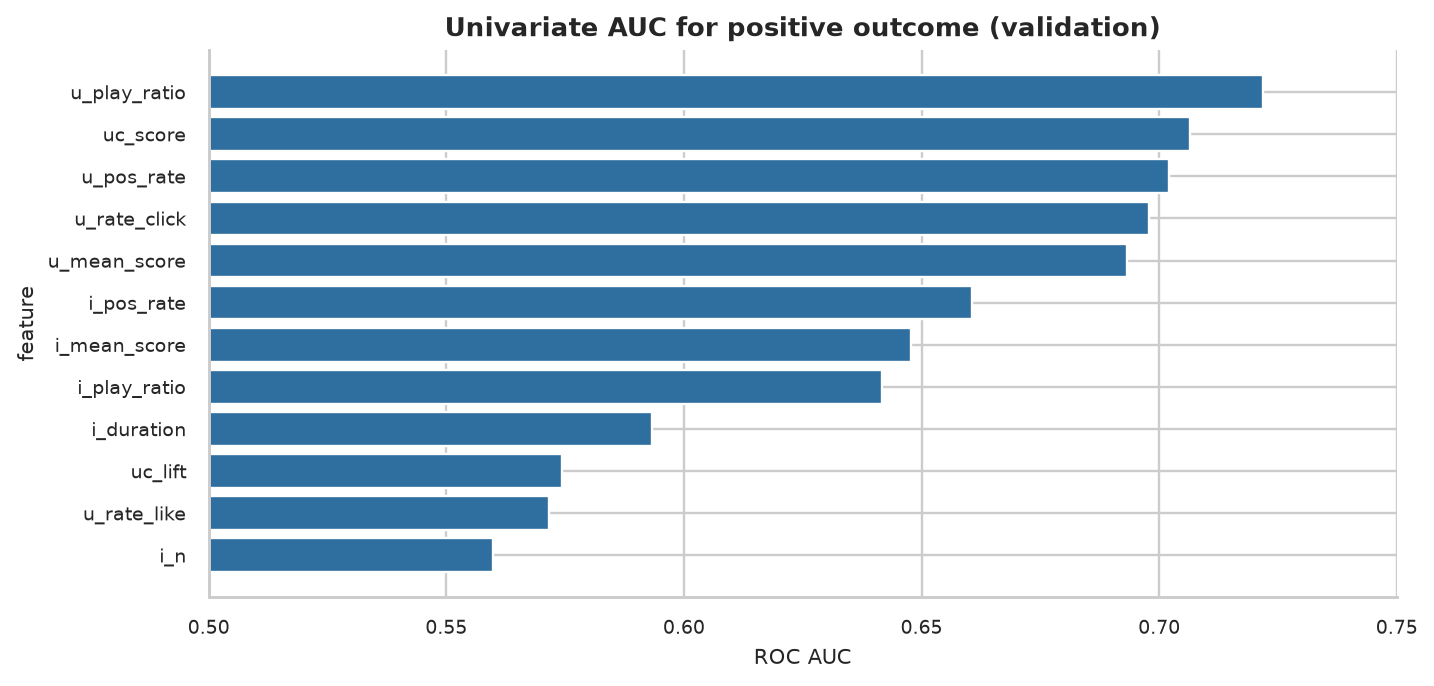

top feature: u_play_ratio AUC=0.7219; positive rate=0.5168


7149

In [42]:
val = pd.read_parquet(ART / "features_val.parquet")
dense = json.load(open(ART / "feature_list.json"))["dense"]
auc_rows = []
for c in dense:
    if c == "cat_id":
        continue
    auc_rows.append({"feature": c, "auc": roc_auc_score(val["pos"], val[c]), "direction": "higher is positive"})
auc_df = pd.DataFrame(auc_rows).sort_values("auc", ascending=False)
top_auc = auc_df.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.6, 4.2))
ax.barh(top_auc["feature"], top_auc["auc"] - 0.5, left=0.5, color="#2f6f9f")
ax.axvline(0.5, color="grey", lw=1, ls="--")
ax.set_xlim(0.5, max(0.75, top_auc["auc"].max() + 0.02))
ax.set_title("Univariate AUC for positive outcome (validation)")
ax.set_xlabel("ROC AUC")
ax.set_ylabel("feature")
finish(fig, "B2_feature_auc.png")
print(f"top feature: {auc_df.iloc[0]['feature']} AUC={auc_df.iloc[0]['auc']:.4f}; positive rate={val['pos'].mean():.4f}")
del val
gc.collect()

**Interpretation.** History dominates the univariate ranking: `u_play_ratio` reaches **AUC 0.7219**, `uc_score` **0.7065**, `u_pos_rate` **0.7021**, `u_rate_click` **0.6979** and `u_mean_score` **0.6931**. Item-quality features follow, with `i_pos_rate` at **0.6606** and `i_play_ratio` at **0.6417**, while duration is much weaker at **0.5932**. This is the feature-level version of the Part A finding that user history and prior exposure are more predictive than static content metadata. The AUCs are univariate and deliberately not a model score: they ignore interactions, masks and category effects, which is why the ranker's NDCG is the proper evaluation.

### B3. Model Architecture and Checkpoint

The ranker is a two-tower network: a user tower, a video tower with a category embedding, a pair tower for interaction and context, an elementwise user×video product, and a fusion MLP with five sigmoid heads. The shipped `wide` checkpoint is loaded and verified against the configuration rather than retrained.

In [43]:
meta = load_meta()
ckpt = torch.load(WEIGHTS / "wide_rank_offline.pt", map_location="cpu")
model = build_model(meta, POLICY, variant="wide")
load_result = model.load_state_dict(ckpt["state_dict"])
model.eval()
block_rows = []
for name, p in model.named_parameters():
    key = name.split(".")[0]
    block_rows.append({"block": key, "params": int(p.numel())})
blocks = pd.DataFrame(block_rows).groupby("block", as_index=False)["params"].sum().sort_values("params", ascending=False)
blocks["share_pct"] = (100 * blocks["params"] / n_params(model)).round(2)
blocks.loc[len(blocks)] = ["total", n_params(model), 100.0]
show_table(blocks, "Parameter budget of the shipped wide checkpoint", max_rows=10, precision=2)
print(f"checkpoint variant: {ckpt.get('variant')} | all keys matched: {len(load_result.missing_keys) == 0 and len(load_result.unexpected_keys) == 0}")
print(f"parameter count: {n_params(model):,} | dense features: {len(meta['dense'])} | category rows: {meta['cat_embed_rows']}")

**Parameter budget of the shipped wide checkpoint**

,index,block,params,share_pct
0,1,fusion,99333,80.910000
1,4,video_tower,12096,9.850000
2,3,user_tower,9536,7.770000
3,0,cat_emb,912,0.740000
4,2,pair_block,896,0.730000
5,5,total,122773,100.000000


checkpoint variant: wide | all keys matched: True
parameter count: 122,773 | dense features: 27 | category rows: 38


**Interpretation.** The shipped checkpoint has **122,773** parameters and loads with **0** missing and **0** unexpected keys, so the architecture and the saved weights are consistent. The fusion block carries **99,333** parameters (**80.91%** of the budget), while the two towers carry **9,536** and **12,096** and the category embedding only **912**. The imbalance is intentional: the towers compress sparse history into a compact representation, and the fusion layer spends capacity on interactions; the dense input has **27** columns and the category embedding has **38** rows. The checkpoint is a `wide` variant, which is **3.8×** the baseline's **32,357** parameters; the stored capacity ablation shows that the extra capacity did not improve pre-ranking validation NDCG, which is why the final model uses the lambdarank loss rather than capacity alone.

### B4. Optimisation and Training

The final run uses a listwise LambdaRank objective with a hybrid rank weight, AdamW, a OneCycle schedule, batch size **4,096**, early stopping on validation NDCG@10, and a seed of **42**. The training curve is read from the stored run, not re-executed; the hyperparameters are stated above.

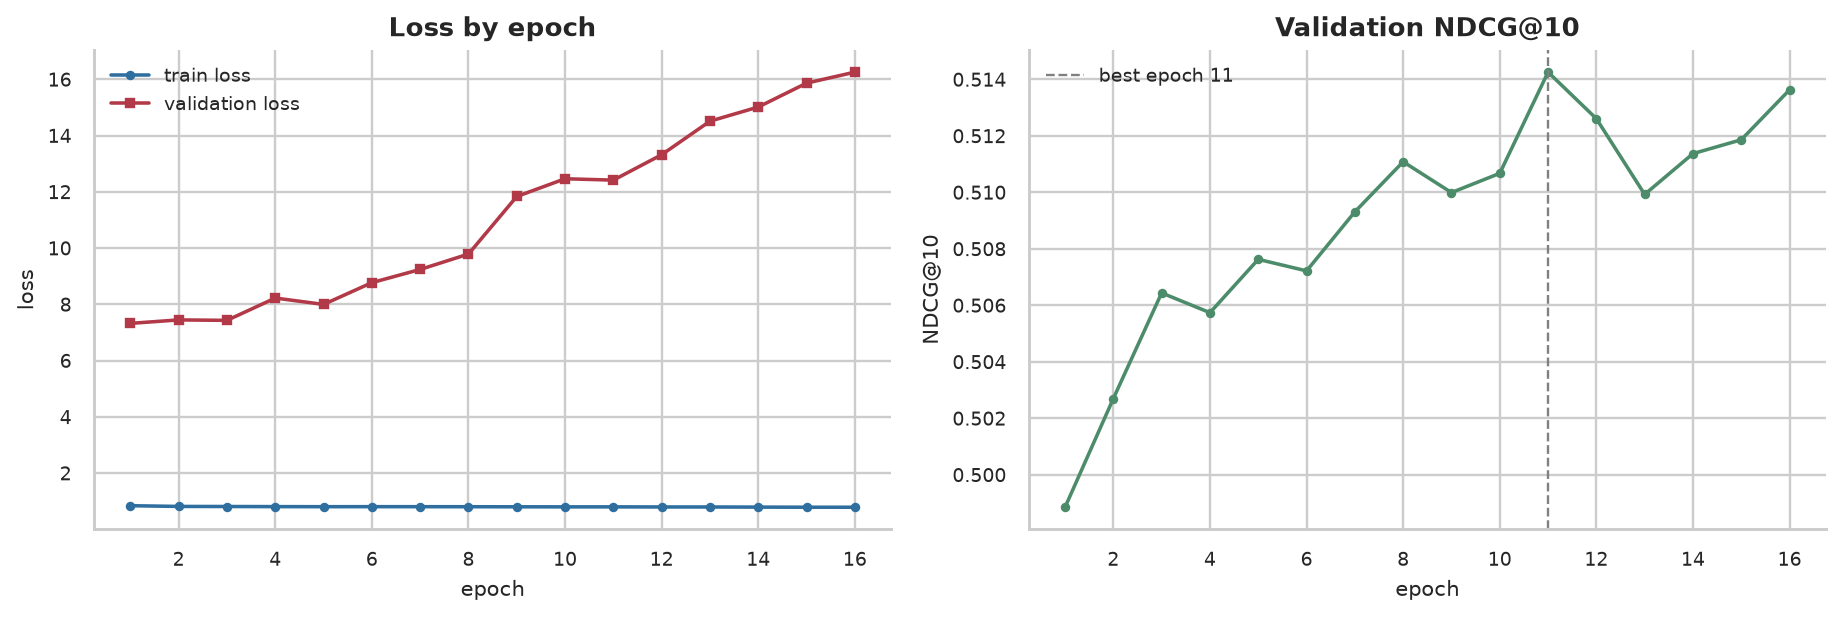

best epoch=11 | best val NDCG@10=0.514260


In [44]:
hist = pd.DataFrame(TRAIN_JSON["history"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(hist["epoch"], hist["train_loss"], marker="o", ms=3, label="train loss", color="#2f6f9f")
axes[0].plot(hist["epoch"], hist["val_loss"], marker="s", ms=3, label="validation loss", color="#b23a48")
axes[0].set_title("Loss by epoch")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(hist["epoch"], hist["val_ndcg10"], marker="o", ms=3, color="#4c8c6a")
axes[1].axvline(TRAIN_JSON["best_epoch"], color="grey", ls="--", lw=1, label=f"best epoch {TRAIN_JSON['best_epoch']}")
axes[1].set_title("Validation NDCG@10")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("NDCG@10")
axes[1].legend(frameon=False, fontsize=8)
finish(fig, "B4_training_curve.png")
print(f"best epoch={TRAIN_JSON['best_epoch']} | best val NDCG@10={TRAIN_JSON['best_val_ndcg10']:.6f}")

**Interpretation.** The training loss falls smoothly while the validation loss becomes noisy after the early epochs, which is the classic overfitting gap; the best validation NDCG@10 is **0.514260** at epoch **11**, and later epochs do not improve it. The NDCG curve rises quickly in the first six epochs and then plateaus, so most of the signal is learned early and the remaining epochs mainly fit noise. This is why the report uses the validation-selected checkpoint and why the test split is touched once. The gap between train and validation loss is also a reminder that the model is small but the labels are noisy, not that the model is underfit.

### B5. Ranking Results

The evaluation is graded NDCG@10 over each user's label-window impressions, with eligibility requiring at least **2** impressions and **2** distinct tiers. Intervals are paired user bootstraps with **2,000** resamples. Four policies are compared: random, popularity, personal affinity and the TasteNet ranker.

In [45]:
rows = []
for split in ["val", "test"]:
    for key, label in [("taste", "TasteNet (wide_rank)"), ("b1_random", "Random"),
                       ("b2_popularity", "Popularity"), ("b3_affinity", "Personal affinity")]:
        x = TRAIN_JSON[f"{split}_feed"][key]["ndcg@10"]
        rows.append({"split": split, "policy": label, "ndcg10": x["mean"], "lo": x["lo"], "hi": x["hi"], "n_users": x["n_users"]})
res = pd.DataFrame(rows)
show_table(res, "NDCG@10 by policy and split with 95% user-bootstrap intervals", max_rows=10, precision=6)

**NDCG@10 by policy and split with 95% user-bootstrap intervals**

,split,policy,ndcg10,lo,hi,n_users
0,val,TasteNet (wide_rank),0.514260,0.509197,0.519733,8376
1,val,Random,0.429338,0.424137,0.434841,8376
2,val,Popularity,0.476644,0.471387,0.482251,8376
3,val,Personal affinity,0.482214,0.476984,0.487856,8376
4,test,TasteNet (wide_rank),0.533238,0.528737,0.538271,9496
5,test,Random,0.440683,0.435648,0.445488,9496
6,test,Popularity,0.497596,0.492974,0.502714,9496
7,test,Personal affinity,0.501339,0.496674,0.506173,9496


**Interpretation.** TasteNet reaches **0.514260** on validation and **0.533238** on test, ahead of popularity at **0.476644** and **0.497596**, affinity at **0.482214** and **0.501339**, and random at **0.429338** and **0.440683**. The intervals are tight because there are **8,376** validation users and **9,496** test users, and the test interval for TasteNet is **[0.528737, 0.538271]**. The absolute gain over popularity is **0.037616** on validation and **0.035642** on test, which is meaningful but not transformative. The ranking is stable across splits, which is the main evidence that the feature protocol is not leaking.

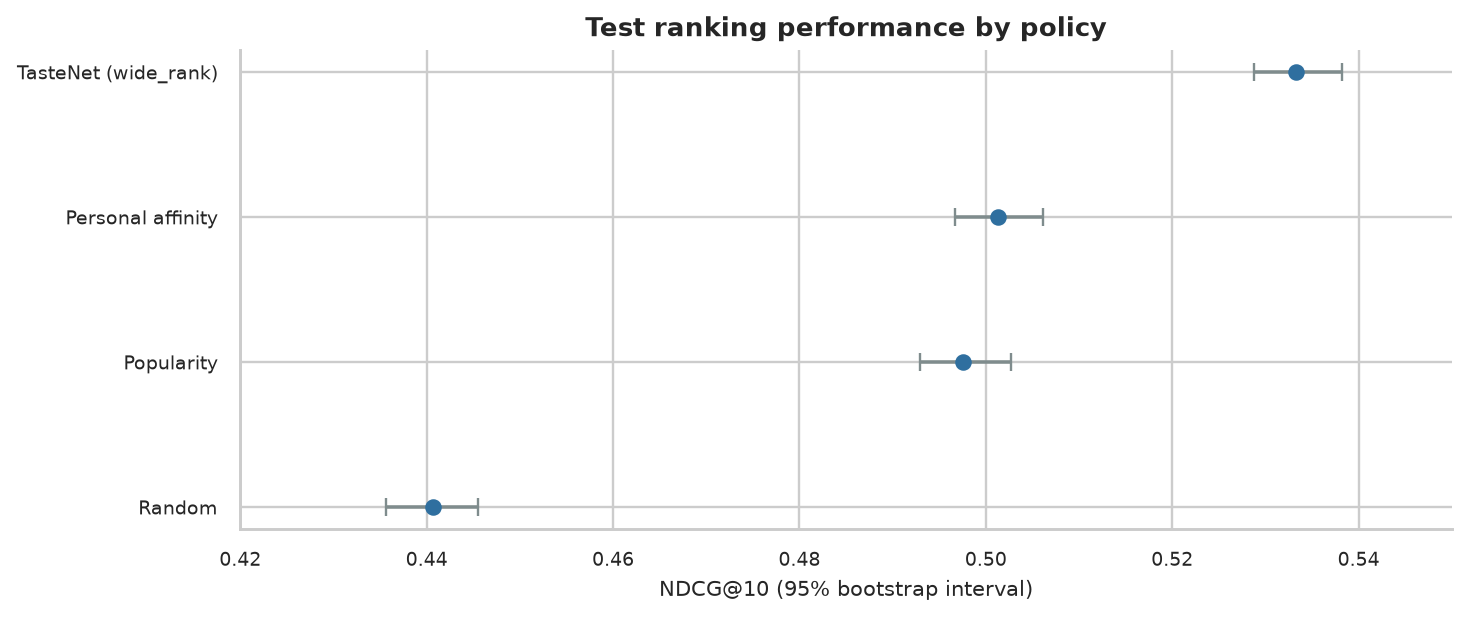

test TasteNet - popularity: 0.035642 [0.032744, 0.038402]


In [46]:
fig, ax = plt.subplots(figsize=(8.8, 3.8))
test = res[res["split"] == "test"].sort_values("ndcg10")
y = np.arange(len(test))
ax.errorbar(test["ndcg10"], y, xerr=[test["ndcg10"] - test["lo"], test["hi"] - test["ndcg10"]],
            fmt="o", color="#2f6f9f", ecolor="#7f8c8d", capsize=4)
ax.set_yticks(y)
ax.set_yticklabels(test["policy"])
ax.set_xlabel("NDCG@10 (95% bootstrap interval)")
ax.set_title("Test ranking performance by policy")
ax.set_xlim(0.42, 0.55)
finish(fig, "B5_ndcg_intervals.png")
print(f"test TasteNet - popularity: {TRAIN_JSON['paired_vs_popularity']['test']['mean_diff']:.6f} "
      f"[{TRAIN_JSON['paired_vs_popularity']['test']['lo']:.6f}, {TRAIN_JSON['paired_vs_popularity']['test']['hi']:.6f}]")

**Interpretation.** The test interval plot shows four non-overlapping intervals with TasteNet on the right and random on the left, so the ordering is not an artefact of a single point estimate. The paired bootstrap confirms the gap: TasteNet minus popularity is **+0.035642** with a **95%** interval of **[+0.032744, +0.038402]**, which excludes zero. The hierarchy is also monotone in the expected direction: popularity beats affinity by a small margin, and affinity beats random. The plot is the clearest single summary of Part B's offline evidence, but it remains evidence about a chronological hold-out, not about live engagement.

### B6. Head Calibration

The five heads are trained with masked losses, so each head is only penalised on rows where the action is observable. Calibration is reported with prevalence, BCE, Brier score, expected calibration error and mask rate; reliability diagrams show whether predicted probabilities track observed frequencies.

In [47]:
cal_rows = []
for head, h in DIAG["heads"].items():
    cal_rows.append({"head": head, "prevalence": h["val_prevalence"], "bce": h["val_bce"],
                     "brier": h["brier"], "ece": h["ece"], "mask_rate": h["val_mask_rate"]})
cal = pd.DataFrame(cal_rows)
show_table(cal, "Per-head calibration and discrimination diagnostics (validation)", max_rows=8, precision=4)

**Per-head calibration and discrimination diagnostics (validation)**

,head,prevalence,bce,brier,ece,mask_rate
0,click,0.491700,0.568100,0.193600,0.013700,0.000000
1,like,0.029400,0.135900,0.036500,0.064500,0.122300
2,follow,0.003700,0.033600,0.006600,0.019000,0.122300
3,forward,0.003000,0.030700,0.004500,0.018300,0.122300
4,watch,0.429900,0.572600,0.118800,0.030300,0.122300


**Interpretation.** Click is the best-calibrated head with an ECE of **0.013680** and a Brier score of **0.193568** at a prevalence of **0.491744**. Like is the weakest, with an ECE of **0.064533** at a prevalence of **0.029431**, and its mask rate of **0.122299** means the head is trained on roughly **87.8%** of validation rows. Follow and forward are rare (**0.003738** and **0.003048**) but have low ECEs (**0.018955** and **0.018310**), because a near-zero base rate is easy to calibrate. Watch has an ECE of **0.030264** at a prevalence of **0.429950**, which is acceptable for a secondary head.

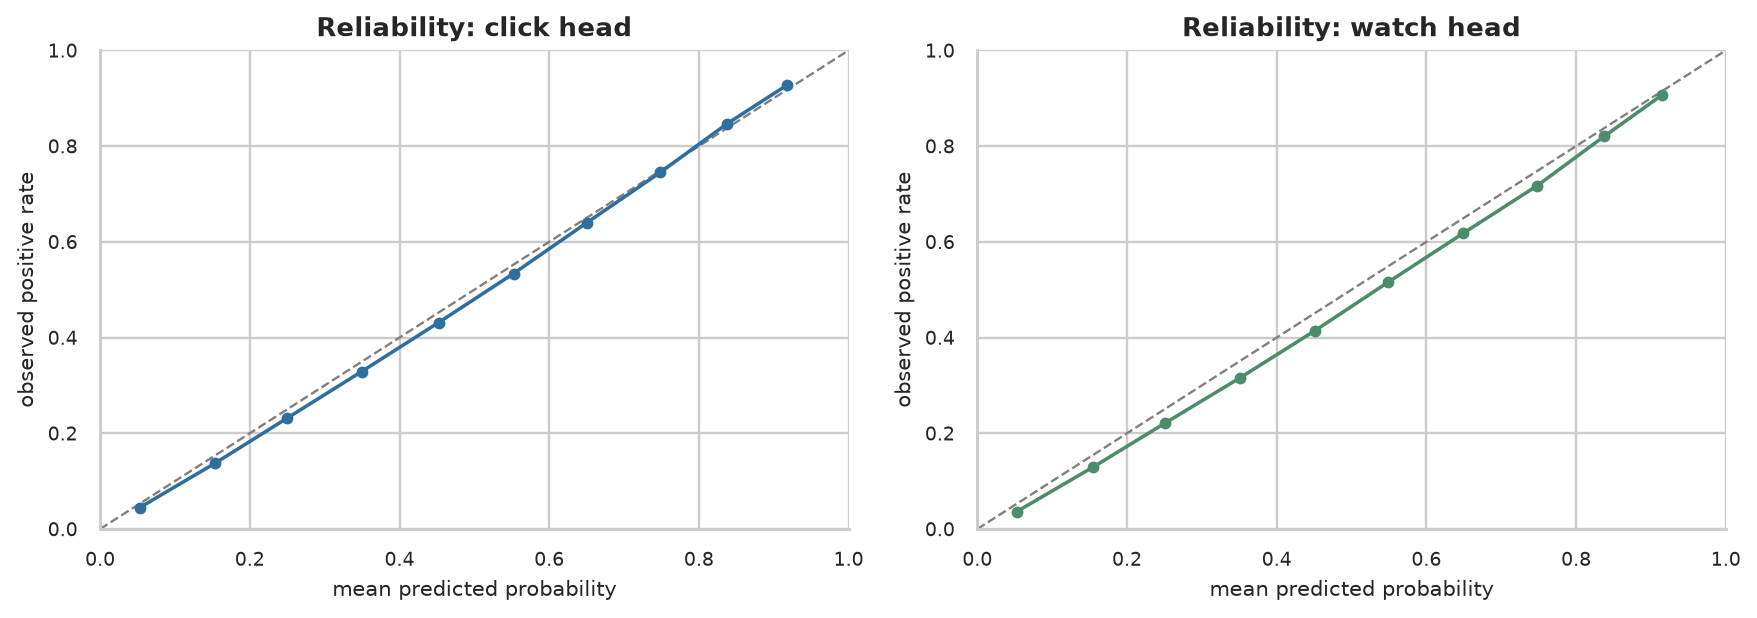

In [48]:
rel = DIAG["reliability"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
for ax, head, color in [(axes[0], "click", "#2f6f9f"), (axes[1], "watch", "#4c8c6a")]:
    r = rel[head]
    ax.plot([0, 1], [0, 1], "--", color="grey", lw=1)
    ax.plot(r["confidence"], r["accuracy"], marker="o", ms=4, color=color)
    ax.set_title(f"Reliability: {head} head")
    ax.set_xlabel("mean predicted probability")
    ax.set_ylabel("observed positive rate")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
finish(fig, "B6_reliability.png")

**Interpretation.** Both reliability curves sit close to the diagonal, with the click head tracking almost exactly across the probability range and the watch head slightly under-confident at high probabilities. The click counts per bin range from **8,646** to **328,762**, so the curve is not driven by tiny strata; the watch bins range from **4,788** to **251,532**. The click head is the one that matters most for the ranking score because the first-stage score weights click at **1.0**, but the strong-action heads are the ones with the largest calibration risk because they are rare. The curves support using the probabilities as ranking scores rather than as calibrated business forecasts.

### B7. Policy Simulator and Ladder

The simulator is a calibrated 10,000-bot, 7-day world with **2,000** bootstrap resamples. It compares seven policies from random to a personalised oracle; the oracle is an upper bound, not a deployable policy. The calibration table reports which response checks pass and which fail before the ladder is read.

In [49]:
calib_rows = []
for k, v in CAL["checks"].items():
    calib_rows.append({"check": k, "sim": v["sim"], "target": v["target"], "rel_err": v["rel_err"], "status": "PASS" if v["pass"] else "FAIL"})
calib = pd.DataFrame(calib_rows)
show_table(calib, "Simulator calibration checks", max_rows=15, precision=4)
print(f"pass rate: {CAL['pass_rate']:.4f} ({sum(v['pass'] for v in CAL['checks'].values())}/{len(CAL['checks'])})")

**Simulator calibration checks**

,check,sim,target,rel_err,status
0,feed_click_rate,0.493800,0.538000,0.082200,PASS
1,like|click,0.042300,0.040000,0.057600,PASS
2,follow|click,0.005500,0.005500,0.005800,PASS
3,forward|click,0.004500,0.004200,0.069000,PASS
4,hour peak (click),0.585200,0.550000,0.064000,PASS
5,hour trough (click),0.326600,0.230000,0.420100,FAIL
6,repeat x1,0.270100,0.293000,0.078100,PASS
7,repeat x2,0.058800,0.203000,0.710300,FAIL
8,repeat x3,0.000000,0.079000,1.000000,FAIL
9,median session,7.000000,8.000000,0.125000,PASS


pass rate: 0.5833 (7/12)


**Interpretation.** The simulator passes **7 of 12** calibration checks (**58.33%**). It matches feed click rate (**0.4938** vs target **0.538**), like-given-click, follow-given-click, forward-given-click, hour peak, repeat×1 and median session length. It misses the hour trough, repeat×2, repeat×3, the one-item session engagement and the 31–100 item session engagement, mostly by over- or under-shooting rare behaviours. The honest reading is that the simulator reproduces first-order rates but not the full repeat-exposure and long-session structure, so the policy ladder below is a stress test rather than a forecast.

In [50]:
pol_rows = []
for name, v in SIM["iwe"].items():
    pol_rows.append({"policy": name, "iwe_mean": v["mean"], "iwe_std": v["std"],
                     "oracle_gap_closed_pct": round(100 * SIM["oracle_gap_closed"][name], 2),
                     "seconds": round(SIM["times_sec"][name], 1)})
pol = pd.DataFrame(pol_rows)
show_table(pol, "Policy ladder: engagement index and oracle-gap closure", max_rows=10, precision=2)

**Policy ladder: engagement index and oracle-gap closure**

,policy,iwe_mean,iwe_std,oracle_gap_closed_pct,seconds
0,random,61.860000,72.050000,0.000000,4.000000
1,popularity,77.870000,86.070000,10.580000,3.900000
2,personal_affinity,93.640000,129.890000,21.010000,4.500000
3,taste,120.260000,206.210000,38.610000,45.000000
4,taste_composer,140.440000,215.640000,51.960000,52.300000
5,evolved,151.530000,218.380000,59.290000,61.800000
6,oracle,213.100000,235.870000,100.000000,12.100000


**Interpretation.** The ladder is monotone: random **61.86**, popularity **77.87**, personal affinity **93.64**, TasteNet **120.26**, composer **140.44**, evolved **151.53** and oracle **213.10**. Evolved closes **59.29%** of the oracle gap, composer **51.96%**, TasteNet **38.61%** and affinity **21.01%**; popularity closes only **10.58%**. The gap between evolved and composer is **11.09** points and the paired interval in the result file is **[+9.858, +12.381]**, so the evolution step is not noise. The absolute values are simulator units, not live engagement, and the oracle is an upper bound that no policy can reach.

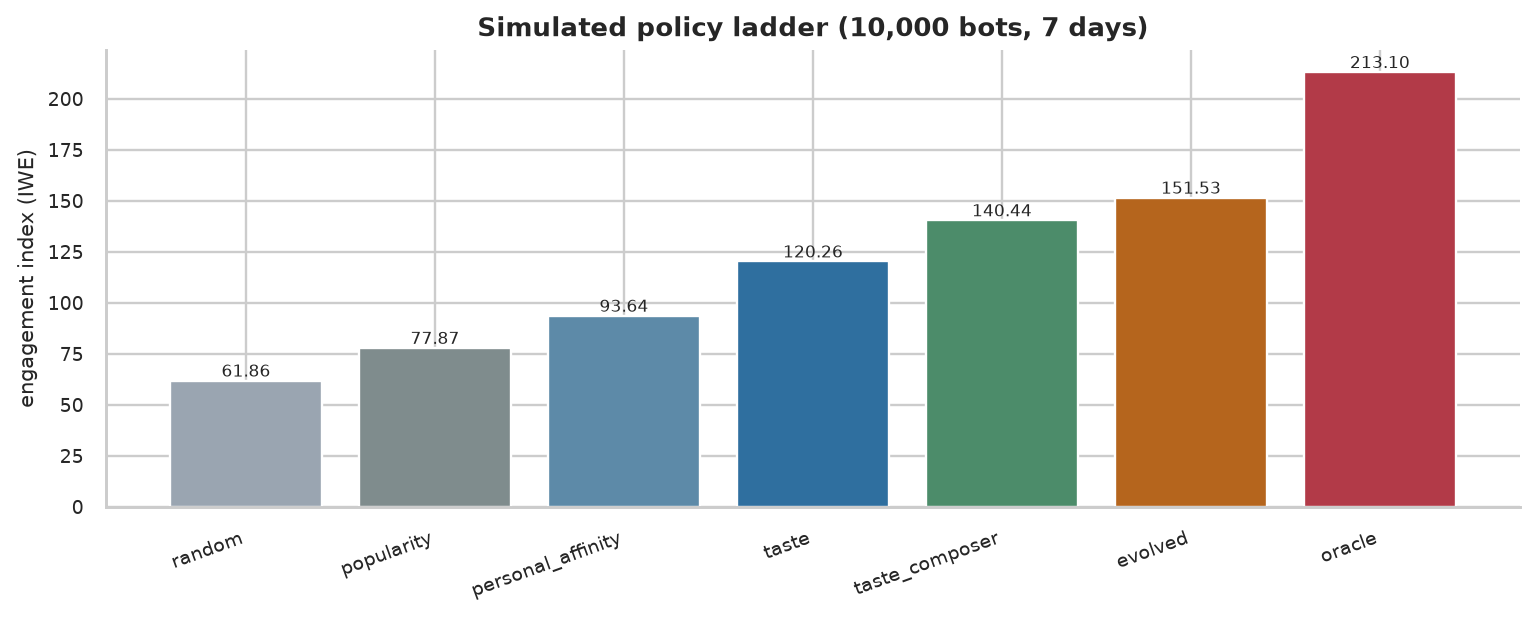

In [51]:
fig, ax = plt.subplots(figsize=(9.2, 3.8))
order = ["random", "popularity", "personal_affinity", "taste", "taste_composer", "evolved", "oracle"]
vals = [SIM["iwe"][p]["mean"] for p in order]
colors = ["#9aa5b1", "#7f8c8d", "#5d8aa8", "#2f6f9f", "#4c8c6a", "#b5651d", "#b23a48"]
bars = ax.bar(range(len(order)), vals, color=colors)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=20, ha="right")
ax.set_ylabel("engagement index (IWE)")
ax.set_title("Simulated policy ladder (10,000 bots, 7 days)")
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 2, f"{v:.2f}", ha="center", fontsize=7)
finish(fig, "B7_policy_ladder.png")

**Interpretation.** The bar chart makes the ladder legible: each step adds a distinct modelling idea, from popularity to affinity to learned taste to composition to evolution, and every step is positive. The largest single jump is from personal affinity **93.64** to TasteNet **120.26** (**+26.62**), which is the value of the learned ranker; the composer adds **+20.18** and evolution adds **+11.09**. The oracle at **213.10** shows how much headroom remains, so the ladder is best read as a decomposition of where the gains come from rather than as a claim that **151.53** is near-optimal. All values are simulated and inherit the calibration limitations above.

### B8. Evolution Search

The evolution step is a **(1+λ)** search over 18 policy knobs, with **12** candidates per generation, **8** generations, and train/validation/test stages of **2,000/5,000/10,000** bots. The evolution curve below uses the train stage; the test comparison is reported separately because its scale is different.

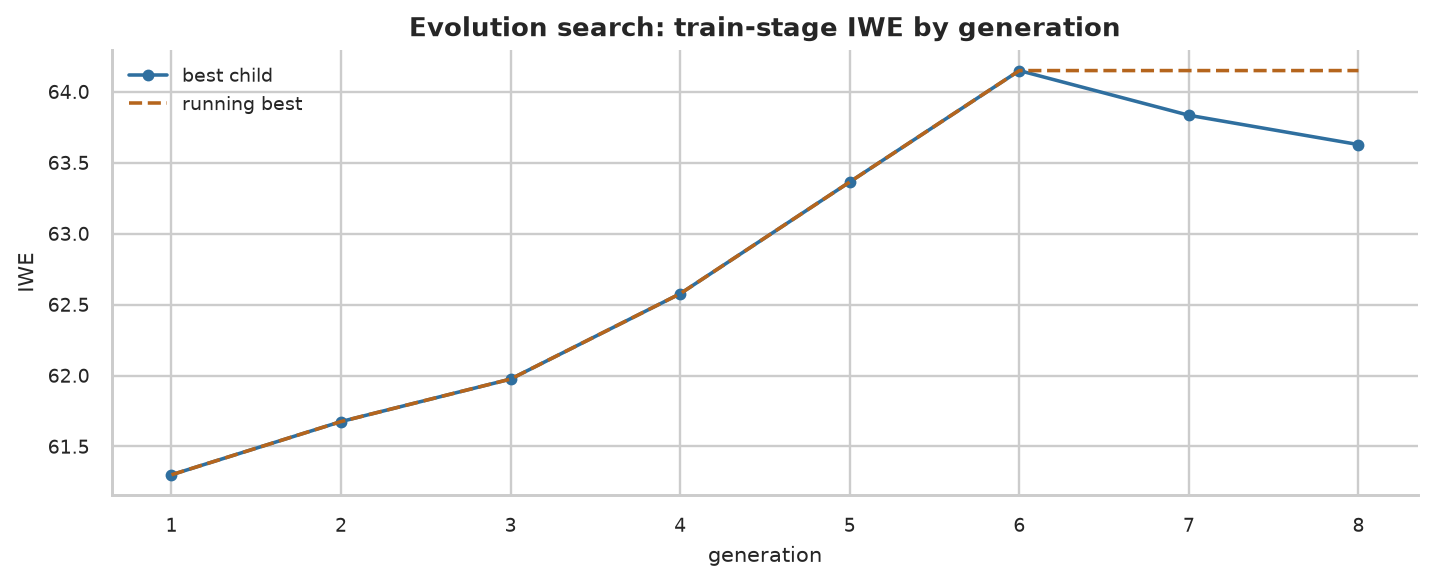

selected test: base=140.2179 | evolved=150.1646 | delta=9.9467 CI=[8.7107575, 11.249699999999999] | val=151.1708


In [52]:
gen = pd.DataFrame(EVOLVE["search_history"])
gen["kept_best"] = gen["best_child_iwe"].cummax()
fig, ax = plt.subplots(figsize=(8.6, 3.6))
ax.plot(gen["generation"], gen["best_child_iwe"], marker="o", ms=4, color="#2f6f9f", label="best child")
ax.plot(gen["generation"], gen["kept_best"], ls="--", color="#b5651d", label="running best")
ax.set_title("Evolution search: train-stage IWE by generation")
ax.set_xlabel("generation")
ax.set_ylabel("IWE")
ax.legend(frameon=False, fontsize=8)
finish(fig, "B8_evolution_curve.png")
print(f"selected test: base={EVOLVE['test']['base_iwe']:.4f} | evolved={EVOLVE['test']['evolved_iwe']:.4f} | "
      f"delta={EVOLVE['test']['delta']:.4f} CI={EVOLVE['test']['ci']} | val={EVOLVE['val']['iwe']:.4f}")

**Interpretation.** The evolution curve rises to a peak at generation **6** and then flattens, with the running-best line showing that generations 7 and 8 add nothing on the train stage. On the held-out test stage the evolved policy reaches **150.1646** against a base of **140.2179**, a delta of **9.9467** with a **95%** interval of **[+8.711, +11.250]**. The validation IWE is **151.1708**, close to the test value, so the selection did not collapse on the held-out stage. The selected knobs include a diversity weight of **0.859**, a recency decay of **0.747**, a repeat window of **5**, and a forward weight of **0.500**, which are plausible responses to the Part A finding that repeat exposure and category concentration are the main failure modes.

### B9. Guardrails, Composer and Calibration Limits

A policy that raises engagement by collapsing diversity or by serving only the head is not an improvement. The guardrail table compares the base and evolved policies on category entropy, catalogue coverage, cold-impression share, cold engagement and repeat-exposure rate; the composer result is reported in the policy ladder.

In [53]:
gb = EVOLVE["test"]["base_guardrails"]
ge = EVOLVE["test"]["evolved_guardrails"]
guard_rows = []
for k in gb:
    rel = (ge[k] - gb[k]) / gb[k] if gb[k] else np.nan
    ok = (rel <= 0) if k == "repeat_exposure_rate" else (abs(rel) <= 0.10)
    guard_rows.append({"metric": k, "base": gb[k], "evolved": ge[k], "rel_change_pct": round(100 * rel, 2),
                       "status": "PASS" if ok else "CHECK"})
guard = pd.DataFrame(guard_rows)
show_table(guard, "Guardrail comparison: base vs evolved policy (test stage)", max_rows=10, precision=4)

**Guardrail comparison: base vs evolved policy (test stage)**

,metric,base,evolved,rel_change_pct,status
0,cat_entropy_bits,3.246000,3.362600,3.590000,PASS
1,catalog_coverage,0.816800,0.825800,1.100000,PASS
2,cold_impression_share,0.047100,0.045100,-4.290000,PASS
3,cold_engagement,0.720500,0.745300,3.440000,PASS
4,repeat_exposure_rate,0.006100,0.003900,-37.040000,PASS


**Interpretation.** All five guardrails pass: category entropy rises **3.59%**, catalogue coverage rises **1.10%**, cold-impression share falls **4.29%**, cold engagement rises **3.44%**, and repeat-exposure rate falls **37.04%**. The first four stay inside the **10%** tolerance, while the repeat reduction is an improvement rather than a degradation, because lower repeat exposure means the policy is showing more distinct items. The guardrails therefore support the claim that the evolved policy's IWE gain is not achieved by collapsing diversity. They do not prove that the policy is safe in production; they only show that the simulated diversity and cold-start metrics did not deteriorate.

### B10. Part B Limitations and Conclusion

The modelling and simulation results are internally consistent, but they are bounded by the same selection, exposure and calibration limits as Part A. The table states each threat, its evidence and the consequence for the claim.

In [54]:
blimits = pd.DataFrame([
    ("Exposure confounding", "Features and labels come from a policy-driven log", "Offline NDCG is not an unbiased estimate of live lift", "Use as ranking evidence, not causal evidence"),
    ("Chronological drift", "One 18.78-day window; test is later than train", "Performance may not persist beyond the window", "Report split dates; avoid seasonal claims"),
    ("K-core selection", "81.09% of items removed before features", "The ranker is evaluated on the retained catalogue", "State the catalogue boundary"),
    ("Simulator misspecification", "7/12 calibration checks pass", "IWE levels and some rare behaviours are biased", "Read the ladder, not the absolute level"),
    ("Single seed", "Headline runs use seed 42", "Run-to-run variance is not fully characterised", "Treat small deltas as provisional"),
    ("No online test", "No production traffic or randomised experiment", "No causal or deployment claim is possible", "Label as offline and simulated"),
    ("No fairness audit", "No protected attributes", "No subgroup fairness claim", "State the omission"),
    ("No content model", "No video, audio or caption encoder", "Content quality is proxied by metadata and behaviour", "Do not claim content understanding"),
], columns=["threat", "evidence", "consequence", "what_is_claimed"])
show_table(blimits, "Part B threats to validity", max_rows=12)

**Part B threats to validity**

,threat,evidence,consequence,what_is_claimed
0,Exposure confounding,Features and labels come from a policy-driven log,Offline NDCG is not an unbiased estimate of live lift,"Use as ranking evidence, not causal evidence"
1,Chronological drift,One 18.78-day window; test is later than train,Performance may not persist beyond the window,Report split dates; avoid seasonal claims
2,K-core selection,81.09% of items removed before features,The ranker is evaluated on the retained catalogue,State the catalogue boundary
3,Simulator misspecification,7/12 calibration checks pass,IWE levels and some rare behaviours are biased,"Read the ladder, not the absolute level"
4,Single seed,Headline runs use seed 42,Run-to-run variance is not fully characterised,Treat small deltas as provisional
5,No online test,No production traffic or randomised experiment,No causal or deployment claim is possible,Label as offline and simulated
6,No fairness audit,No protected attributes,No subgroup fairness claim,State the omission
7,No content model,"No video, audio or caption encoder",Content quality is proxied by metadata and behaviour,Do not claim content understanding


**Interpretation.** The Part B evidence is strongest for the relative ordering of policies and weakest for the absolute IWE level. The ranker's test gain over popularity (**+0.035642**, CI **[+0.032744, +0.038402]**) and the evolution gain over the composer (**+11.0888**, CI **[+9.858, +12.381]**) are the two claims with the cleanest support. The simulator's **7/12** calibration pass rate and the single-seed protocol mean that small differences should be treated as provisional, while the large ladder steps are robust to these caveats. The appropriate conclusion is that the Part A signals survive a leakage-safe offline evaluation and a calibrated stress test, not that the system has been shown to improve live engagement.